# Part A · Rebuild nine charts, then take them apart (36 marks)

For each case: **(1) rebuild** the published chart from its recipe and hit the self-check number, **(2) the conclusion and the decoy**, **(3) the mechanism** with the number that proves it, **(4) the redesign**, actually plotted.

> "Correlation is not causation" scores zero here: it names no mechanism. Each case below names *which* variable and shows *the number*.

**Run order:** *Run All*. Needs `vizlib.py` and `data/` (see README). Every figure is saved to `outputs/` **before** it is shown. The recipe rebuilds are deliberately the *published* (flawed) charts, including the dual-axis one in case 7, which is the only dual-axis chart in this work and exists to be taken apart.

In [2]:
# --- Setup: finds vizlib.py and data/ wherever this notebook is saved ---------------
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

def find_assignments_dir():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        for cand in (p, p / "assignments", p / "week3" / "assignments"):
            if (cand / "vizlib.py").exists() and (cand / "data").is_dir():
                return cand
    raise FileNotFoundError(
        "Could not find vizlib.py + data/. Save this notebook inside "
        "week3/assignments/ (next to vizlib.py) - see README.md.")

ROOT = Path(r"C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 3")
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"
OUT = ROOT / "outputs"            # every PNG this notebook writes lands here
OUT.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from vizlib import (PALETTE, MARKERS, style_defaults, save_fig, lie_factor,
                    lie_verdict, simulate_cvd, worst_pair, verdict, delta_e)

style_defaults()                  # house look, set once (slide 26)
BLUE, ORANGE, GREEN = PALETTE["series"]
print("ROOT:", ROOT)
from scipy import stats

def finish(fig, name, note=None):
    """Save BEFORE show (the other way round writes a blank file)."""
    save_fig(fig, OUT / f"{name}.png", note)
    plt.show()

SYN = "Synthetic data generated for CDB601220."
SUMMARY = []        # one row per case, printed at the end

ROOT: C:\Users\Nas Graphy\Downloads\Data-Visualization\Week 3


---
## Case 1 · "Premium-certified helmets have 2.5x the head-injury rate"
*Recipe: sum `head_injuries` and `trips` by `helmet_grade`; injuries per 1,000 trips; bar chart from zero.*

              head_injuries  trips  per_1000
helmet_grade                                
Standard                129  60000      2.15
Premium                 216  40000      5.40


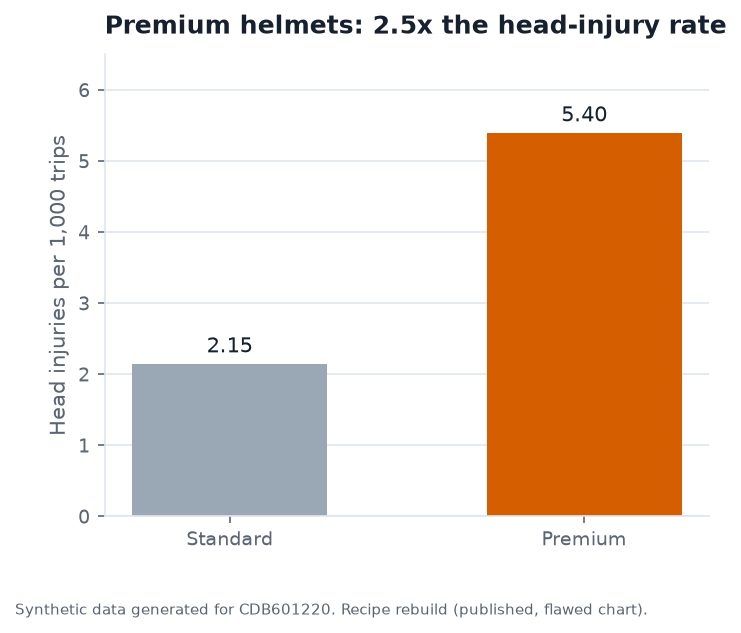

In [5]:
c1 = pd.read_csv(DATA / "case01_helmet_rickshaw.csv")
g = (c1.groupby("helmet_grade")[["head_injuries", "trips"]].sum()
       .assign(per_1000=lambda d: d.head_injuries / d.trips * 1000)
       .loc[["Standard", "Premium"]])
print(g.round(2))
assert round(g.per_1000["Standard"], 2) == 2.15 and round(g.per_1000["Premium"], 2) == 5.40   # self-check

fig, ax = plt.subplots(figsize=(5.2, 4))
bars = ax.bar(g.index, g.per_1000, color=[PALETTE["muted"], PALETTE["highlight"]], width=0.55)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_ylim(0, 6.5)                                  # from zero, as the recipe says
ax.set_ylabel("Head injuries per 1,000 trips")
ax.set_title("Premium helmets: 2.5x the head-injury rate")
ax.grid(axis="x", visible=False)
finish(fig, "A1_rebuild", SYN + " Recipe rebuild (published, flawed chart).")

In [6]:
# --- evidence: test the decoy, then find the mechanism ---------------------------------
print("DECOY test: are Premium riders less experienced? (months_experience, mean)")
print(c1.groupby("helmet_grade")[["months_experience", "avg_speed_kph"]].mean().round(2), "\n")

tab = (c1.groupby(["road_type", "helmet_grade"])
         .agg(riders=("rider_id", "count"), trips=("trips", "sum"),
              injuries=("head_injuries", "sum"), avg_speed=("avg_speed_kph", "mean")))
tab["per_1000"] = tab.injuries / tab.trips * 1000
print("Injury rate within each road type:"); print(tab.round(2), "\n")

share = pd.crosstab(c1.helmet_grade, c1.road_type, values=c1.trips, aggfunc="sum", normalize="index") * 100
print("Where each grade's trips happen (% of trips):"); print(share.round(1), "\n")
road = c1.groupby("road_type")[["head_injuries", "trips"]].sum()
print("Injury rate by road type, all riders:"); print((road.head_injuries / road.trips * 1000).round(2))

DECOY test: are Premium riders less experienced? (months_experience, mean)
              months_experience  avg_speed_kph
helmet_grade                                  
Premium                   31.42          66.95
Standard                  31.50          30.22 

Injury rate within each road type:
                               riders  trips  injuries  avg_speed  per_1000
road_type        helmet_grade                                              
City arterial    Premium           50   5000        11      39.61      2.20
                 Standard         200  20000        60      38.02      3.00
Inner-city lanes Premium           10   1000         1      25.55      1.00
                 Standard         380  38000        53      23.98      1.39
Motorway         Premium          340  34000       204      72.19      6.00
                 Standard          20   2000        16      70.95      8.00 

Where each grade's trips happen (% of trips):
road_type     City arterial  Inner-city lane

**Conclusion the chart invites:** premium helmets are *worse*: riders who wear them are 2.5× as likely to suffer head injuries, so stop buying them.

**The decoy:** *"Premium riders must be less experienced or more reckless."* It does not hold. Mean experience is **31.4 months (Premium) vs 31.5 months (Standard)**: identical. (Premium riders do ride faster on average, 67 vs 30 kph, but within each road type the two grades ride at almost the same speed, e.g. 72.2 vs 71.0 on the motorway. Speed is a *consequence* of which road they are on, not an independent cause.)

**The mechanism: road type is a confounder, and this is Simpson's paradox.** **85% of Premium riders (340 of 400) work the Motorway**, where the injury rate is 6.1 per 1,000 trips for everyone; only **3% of Standard riders (20 of 600)** do. The pooled rate mostly measures *road*, not helmet. **Within every road type Premium has the lower rate:** Motorway 6.00 vs 8.00, City arterial 2.20 vs 3.00, Inner-city lanes 1.00 vs 1.39, so the sign of the effect reverses once the road is held fixed.

**Redesign:** rate by road type with the two grades side by side, plus where each grade's trips happen.

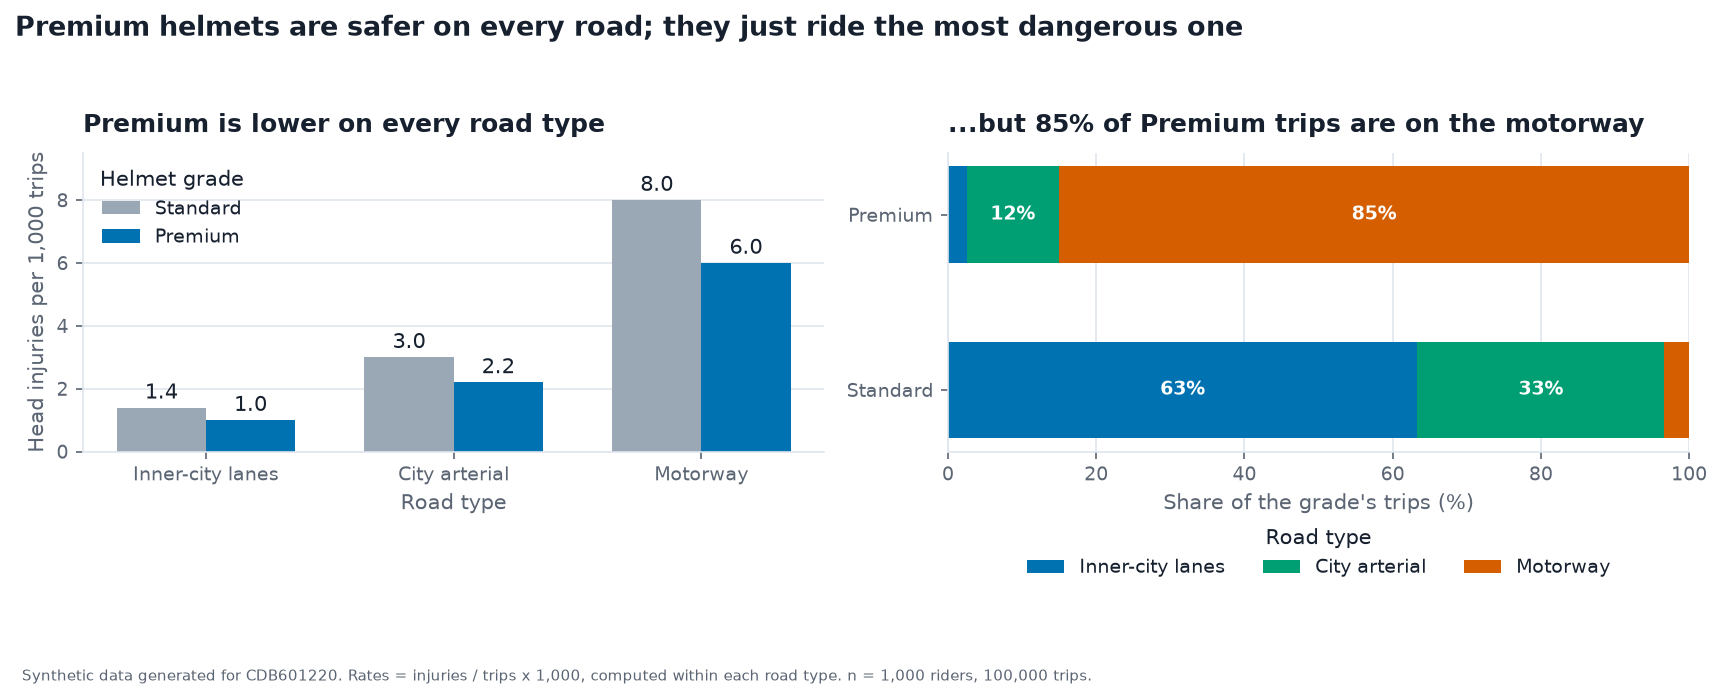

In [7]:
rates = tab.per_1000.unstack("helmet_grade")[["Standard", "Premium"]].loc[["Inner-city lanes", "City arterial", "Motorway"]]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.3))

x = np.arange(3); w = 0.36
b1 = a1.bar(x - w / 2, rates.Standard, w, color=PALETTE["muted"], label="Standard")
b2 = a1.bar(x + w / 2, rates.Premium, w, color=BLUE, label="Premium")
a1.bar_label(b1, fmt="%.1f", padding=2); a1.bar_label(b2, fmt="%.1f", padding=2)
a1.set_xticks(x, rates.index); a1.set_ylim(0, 9.5)
a1.set_ylabel("Head injuries per 1,000 trips"); a1.set_xlabel("Road type")
a1.set_title("Premium is lower on every road type")
a1.legend(title="Helmet grade", loc="upper left"); a1.grid(axis="x", visible=False)

order = ["Inner-city lanes", "City arterial", "Motorway"]
sh = share[order].loc[["Standard", "Premium"]]
left = np.zeros(2)
for road_name, colr in zip(order, [BLUE, GREEN, ORANGE]):
    a2.barh(sh.index, sh[road_name], left=left, color=colr, label=road_name, height=0.55)
    for i, v in enumerate(sh[road_name]):
        if v > 7:
            a2.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += sh[road_name].values
a2.set_xlim(0, 100); a2.set_xlabel("Share of the grade's trips (%)")
a2.set_title("...but 85% of Premium trips are on the motorway")
a2.legend(title="Road type", loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3); a2.grid(axis="y", visible=False)
fig.suptitle("Premium helmets are safer on every road; they just ride the most dangerous one", x=0.006, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
finish(fig, "A1_redesign", SYN + " Rates = injuries / trips x 1,000, computed within each road type. n = 1,000 riders, 100,000 trips.")

SUMMARY.append(dict(case=1, claim="Premium helmets: 2.5x injury rate",
    decoy="Premium riders less experienced? No: 31.4 vs 31.5 months",
    mechanism="Road type confounds (Simpson): 85% of Premium trips on the motorway (6.1/1000); Premium lower within every road",
    number="Motorway 6.00 vs 8.00; 340/400 Premium on motorway"))

---
## Case 2 · "Canteen chai sales predict quiz failures"
*Recipe: scatter `cups_doodh_patti_sold` (x) vs `quiz_failures` (y), one point per month; least-squares line; annotate Pearson r.*

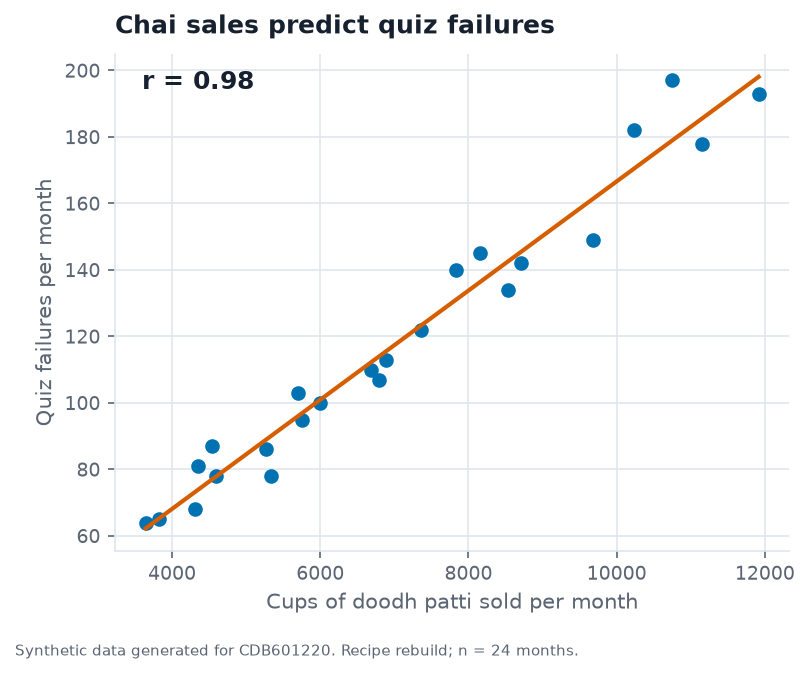

In [8]:
c2 = pd.read_csv(DATA / "case02_chai_quizzes.csv")
r = c2.cups_doodh_patti_sold.corr(c2.quiz_failures)
slope, icpt = np.polyfit(c2.cups_doodh_patti_sold, c2.quiz_failures, 1)
assert round(r, 2) == 0.98                                      # self-check

fig, ax = plt.subplots(figsize=(5.8, 4.3))
ax.scatter(c2.cups_doodh_patti_sold, c2.quiz_failures, color=BLUE, s=36)
xs = np.array([c2.cups_doodh_patti_sold.min(), c2.cups_doodh_patti_sold.max()])
ax.plot(xs, icpt + slope * xs, color=PALETTE["highlight"])
ax.text(0.04, 0.93, f"r = {r:.2f}", transform=ax.transAxes, fontsize=12, fontweight="bold")
ax.set_xlabel("Cups of doodh patti sold per month"); ax.set_ylabel("Quiz failures per month")
ax.set_title("Chai sales predict quiz failures")
finish(fig, "A2_rebuild", SYN + " Recipe rebuild; n = 24 months.")

In [10]:
# --- evidence ----------------------------------------------------------------------------
print("corr(students_enrolled, cups)     =", round(c2.students_enrolled.corr(c2.cups_doodh_patti_sold), 3))
print("corr(students_enrolled, failures) =", round(c2.students_enrolled.corr(c2.quiz_failures), 3))
print(f"enrolment grew {c2.students_enrolled.iloc[0]:,} -> {c2.students_enrolled.iloc[-1]:,}  (x{c2.students_enrolled.iloc[-1]/c2.students_enrolled.iloc[0]:.2f})\n")

# per-student rates remove the head-count
cups_pc = c2.cups_doodh_patti_sold / c2.students_enrolled
fail_per1000 = c2.quiz_failures / c2.students_enrolled * 1000
r_pc, p_pc = stats.pearsonr(cups_pc, fail_per1000)
print(f"per-student r = {r_pc:.2f}  (p = {p_pc:.2f}),  R^2 {r**2:.2f} -> {r_pc**2:.2f}")

def resid(y, X):
    X = np.c_[np.ones(len(X)), X]; return y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
pr = np.corrcoef(resid(c2.cups_doodh_patti_sold.values, c2.students_enrolled.values),
                 resid(c2.quiz_failures.values, c2.students_enrolled.values))[0, 1]
print(f"partial r, holding enrolment fixed = {pr:.2f}  (R^2 {pr**2:.2f})\n")

print("DECOY test: exam months?")
print(c2.groupby("is_exam_month")[["cups_doodh_patti_sold", "quiz_failures"]].mean().round(0))
for flag, d in c2.groupby("is_exam_month"):
    print(f"  r within is_exam_month={flag}: {d.cups_doodh_patti_sold.corr(d.quiz_failures):.3f}  (n={len(d)})")

corr(students_enrolled, cups)     = 0.997
corr(students_enrolled, failures) = 0.977
enrolment grew 1,765 -> 5,406  (x3.06)

per-student r = 0.29  (p = 0.16),  R^2 0.96 -> 0.09
partial r, holding enrolment fixed = 0.46  (R^2 0.21)

DECOY test: exam months?
               cups_doodh_patti_sold  quiz_failures
is_exam_month                                      
0                             6902.0          111.0
1                             7195.0          129.0
  r within is_exam_month=0: 0.996  (n=16)
  r within is_exam_month=1: 0.996  (n=8)


**Conclusion the chart invites:** chai drives failures (or predicts them well): cut canteen chai and fewer students fail. r = 0.98.

**The decoy:** *"Exam months cause both: stress means more chai and more failures."* Exam months do have more failures (129 vs 111 on average), but if exams drove the link, it would **vanish inside each group**. It does not: **r = 0.996 within exam months and 0.996 within non-exam months.** Exam timing is not what holds the two series together.

**The mechanism: head-count.** Enrolment tripled over the 24 months (**1,765 → 5,406, ×3.06**) and *both* series are proportional to it: chai vs enrolment **r = 0.997**, failures vs enrolment **r = 0.977**. More students means more cups *and* more failures. Take the head-count out and the relationship collapses: per student, **r = 0.29 (p = 0.16, not significant), so R² falls from 0.96 to 0.09**. Holding enrolment fixed in a regression, the partial r is 0.46 (R² ≈ 0.21). Some association may remain, but it is a modest fraction of what the 0.98 suggested, and nothing in these data says chai causes it.

**Redesign:** index everything to the first month so the common growth is visible, and plot the per-student rates.

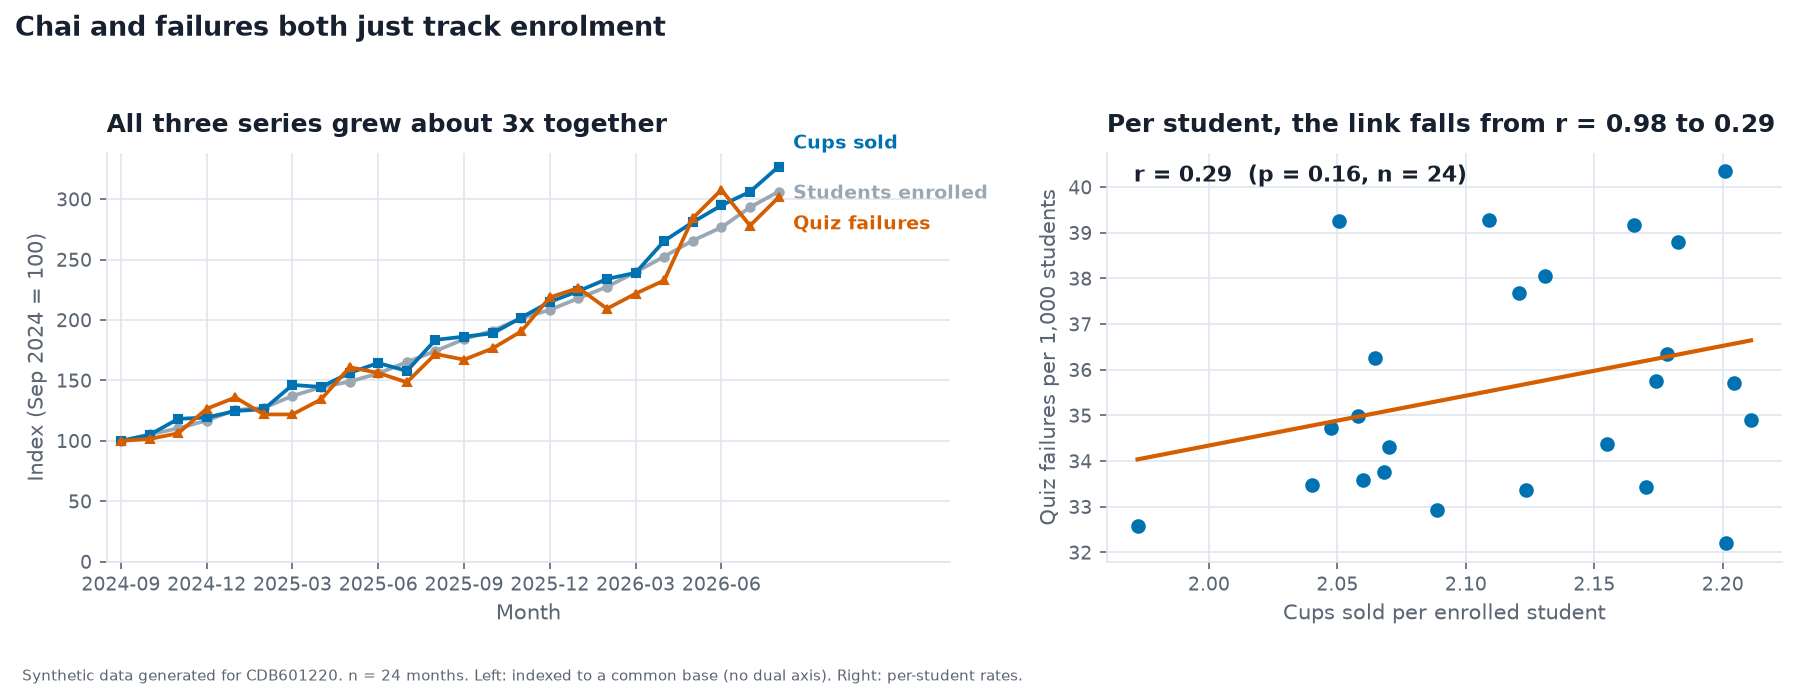

In [11]:
idx = c2.set_index("month")[["students_enrolled", "cups_doodh_patti_sold", "quiz_failures"]]
idx = idx / idx.iloc[0] * 100                          # one common base: Sep 2024 = 100
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.25, 1]})

specs = [("students_enrolled", "Students enrolled", PALETTE["muted"], "o"),
         ("cups_doodh_patti_sold", "Cups sold", BLUE, "s"),
         ("quiz_failures", "Quiz failures", ORANGE, "^")]
for col, lab, colr, mk in specs:
    a1.plot(idx.index, idx[col], color=colr, marker=mk, ms=4, lw=1.8)
    dy = {"cups_doodh_patti_sold": 11, "students_enrolled": -1, "quiz_failures": -13}[col]      # nudge so the labels don't collide
    a1.annotate(lab, xy=(23, idx[col].iloc[-1]), xytext=(7, dy), textcoords="offset points",
                color=colr, va="center", fontsize=9, fontweight="bold")
a1.set_xticks(range(0, 24, 3), idx.index[::3]); a1.set_xlim(-0.5, 29)
a1.set_ylabel("Index (Sep 2024 = 100)"); a1.set_xlabel("Month")
a1.set_title("All three series grew about 3x together"); a1.set_ylim(0)

a2.scatter(cups_pc, fail_per1000, color=BLUE, s=36)
s2, i2 = np.polyfit(cups_pc, fail_per1000, 1); xs = np.array([cups_pc.min(), cups_pc.max()])
a2.plot(xs, i2 + s2 * xs, color=PALETTE["highlight"])
a2.text(0.04, 0.93, f"r = {r_pc:.2f}  (p = {p_pc:.2f}, n = 24)", transform=a2.transAxes, fontsize=10.5, fontweight="bold")
a2.set_xlabel("Cups sold per enrolled student"); a2.set_ylabel("Quiz failures per 1,000 students")
a2.set_title("Per student, the link falls from r = 0.98 to 0.29")
fig.suptitle("Chai and failures both just track enrolment", x=0.006, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
finish(fig, "A2_redesign", SYN + " n = 24 months. Left: indexed to a common base (no dual axis). Right: per-student rates.")

SUMMARY.append(dict(case=2, claim="Chai sales predict quiz failures (r=0.98)",
    decoy="Exam months? No: r stays 0.996 inside exam and non-exam months",
    mechanism="Enrolment tripled (1,765 to 5,406); both series scale with it (r=0.997, 0.977)",
    number="Per-student r = 0.29 (p=0.16); R^2 0.96 -> 0.09"))

---
## Case 3 · "The Smog Action Plan cut Lahore's AQI by a third"
*Recipe: mean `aqi` per `date` across every row; line, **y-axis from zero**; vertical marker at day 61; mean lines for days 1-60 and 61-120.*

before 202   after 137   fall 32%


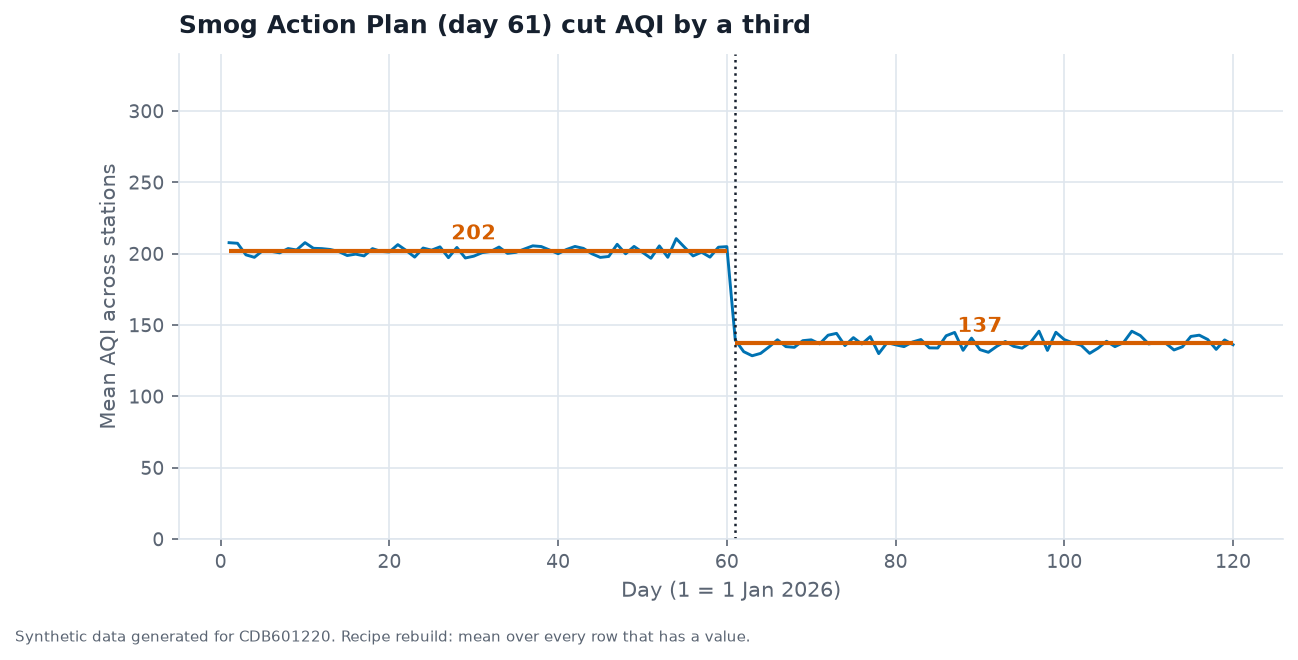

In [12]:
c3 = pd.read_csv(DATA / "case03_aqi_monitors.csv", parse_dates=["date"])
c3["day"] = (c3.date - c3.date.min()).dt.days + 1
daily = c3.groupby("day").aqi.mean()                     # pandas skips blanks silently
before, after = daily.loc[:60].mean(), daily.loc[61:].mean()
print(f"before {before:.0f}   after {after:.0f}   fall {(1 - after / before):.0%}")
assert round(before) == 202 and round(after) == 137 and round((1 - after / before) * 100) == 32   # self-check

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.plot(daily.index, daily.values, color=BLUE, lw=1.4)
ax.axvline(61, color=PALETTE["ink"], ls=":", lw=1.2)
ax.hlines(before, 1, 60, color=PALETTE["highlight"], lw=2); ax.hlines(after, 61, 120, color=PALETTE["highlight"], lw=2)
ax.text(30, before + 8, f"{before:.0f}", ha="center", color=PALETTE["highlight"], fontweight="bold")
ax.text(90, after + 8, f"{after:.0f}", ha="center", color=PALETTE["highlight"], fontweight="bold")
ax.set_ylim(0, 340)                                      # from zero, as the recipe says
ax.set_xlabel("Day (1 = 1 Jan 2026)"); ax.set_ylabel("Mean AQI across stations")
ax.set_title("Smog Action Plan (day 61) cut AQI by a third")
finish(fig, "A3_rebuild", SYN + " Recipe rebuild: mean over every row that has a value.")

In [13]:
# --- evidence ----------------------------------------------------------------------------
reporting = c3.groupby("day").aqi.count()
print("stations reporting on day 1 / 60 / 61 / 120:", reporting.loc[[1, 60, 61, 120]].tolist())
blank = c3[c3.aqi.isna()]
print("blank cells:", len(blank), "| first blank day per station:", sorted(blank.groupby("station_id").day.min().unique()))
print("zones of the 9 stations that went silent:\n", blank.drop_duplicates("station_id").zone.value_counts().to_string(), "\n")
print("mean AQI by zone (days 1-60):"); print(c3[c3.day <= 60].groupby("zone").aqi.mean().round(0).to_string(), "\n")

# like-for-like: only the stations that reported on ALL 120 days
full = c3.groupby("station_id").aqi.count().loc[lambda s: s == 120].index
like = c3[c3.station_id.isin(full)].groupby("day").aqi.mean()
lb, la = like.loc[:60].mean(), like.loc[61:].mean()
print(f"{len(full)} stations reported all 120 days:  before {lb:.1f}   after {la:.1f}   change {(la / lb - 1):+.1%}")

stations reporting on day 1 / 60 / 61 / 120: [22, 22, 13, 13]
blank cells: 540 | first blank day per station: [np.int64(61)]
zones of the 9 stations that went silent:
 zone
Industrial    6
Arterial      3 

mean AQI by zone (days 1-60):
zone
Arterial       245.0
Industrial     322.0
Peri-urban      79.0
Residential    122.0 

13 stations reported all 120 days:  before 137.1   after 137.2   change +0.1%


**Conclusion the chart invites:** the Smog Action Plan, launched on day 61, cut Lahore's air pollution by a third (202 → 137).

**The decoy:** *"It is just seasonal weather: winter smog easing into spring."* If it were, the stations that kept reporting would fall too. They do not. The **13 stations that reported on all 120 days average 137.1 before and 137.2 after (+0.1%)**. Weather moved nothing, and neither did the Plan.

**The mechanism: the set of stations changed on day 61.** Before day 61 all 22 stations reported; from day 61, **9 stations went silent (6 Industrial + 3 Arterial) and only 13 report.** Those are exactly the dirtiest zones (mean AQI **322** Industrial, **245** Arterial, against **122** Residential and **79** Peri-urban). `pandas.mean()` skips blanks without warning, so the "after" average is over a cleaner subset of the city: the denominator changed, not the air. (The y-axis was drawn from zero, as the recipe demands, so truncation is not the issue either.)

**Redesign:** compare like with like, and show the reporting count that explains the published drop.

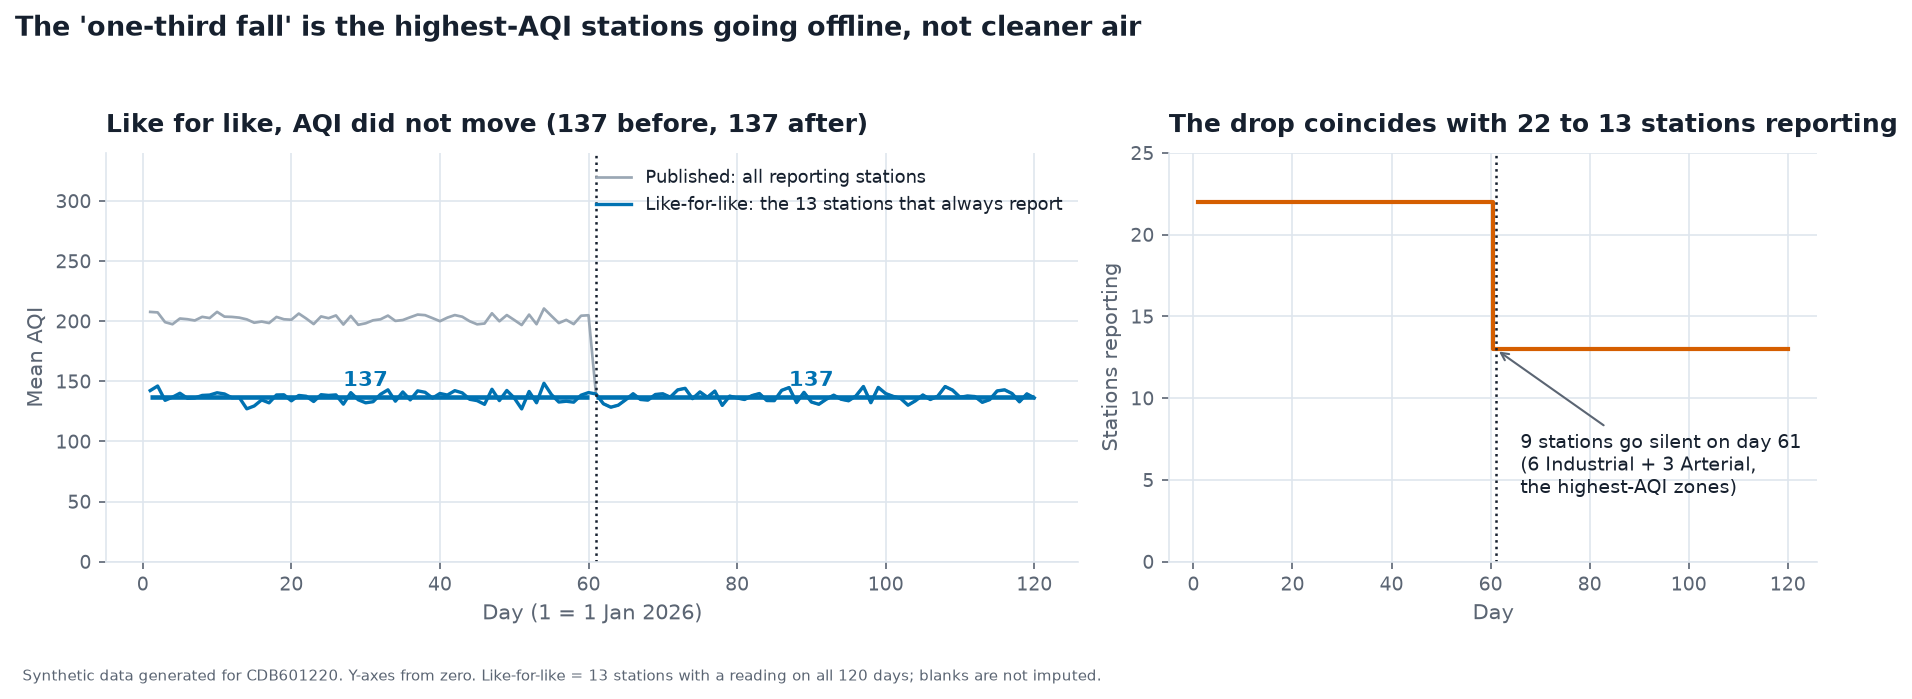

In [14]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw={"width_ratios": [1.5, 1]})
a1.plot(daily.index, daily.values, color=PALETTE["muted"], lw=1.3, label="Published: all reporting stations")
a1.plot(like.index, like.values, color=BLUE, lw=1.6, label=f"Like-for-like: the {len(full)} stations that always report")
a1.hlines(lb, 1, 60, color=BLUE, lw=2.2); a1.hlines(la, 61, 120, color=BLUE, lw=2.2)
a1.text(30, lb + 9, f"{lb:.0f}", ha="center", color=BLUE, fontweight="bold")
a1.text(90, la + 9, f"{la:.0f}", ha="center", color=BLUE, fontweight="bold")
a1.axvline(61, color=PALETTE["ink"], ls=":", lw=1.2)
a1.set_ylim(0, 340); a1.set_xlabel("Day (1 = 1 Jan 2026)"); a1.set_ylabel("Mean AQI")
a1.set_title("Like for like, AQI did not move (137 before, 137 after)")
a1.legend(loc="upper right", fontsize=8.5)

a2.step(reporting.index, reporting.values, where="mid", color=ORANGE, lw=2)
a2.axvline(61, color=PALETTE["ink"], ls=":", lw=1.2)
a2.set_ylim(0, 25); a2.set_xlabel("Day"); a2.set_ylabel("Stations reporting")
a2.annotate("9 stations go silent on day 61\n(6 Industrial + 3 Arterial,\nthe highest-AQI zones)", xy=(61, 13), xytext=(66, 4.2),
            fontsize=9, arrowprops=dict(arrowstyle="->", color=PALETTE["ink_soft"]))
a2.set_title("The drop coincides with 22 to 13 stations reporting")
fig.suptitle("The 'one-third fall' is the highest-AQI stations going offline, not cleaner air", x=0.006, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
finish(fig, "A3_redesign", SYN + " Y-axes from zero. Like-for-like = 13 stations with a reading on all 120 days; blanks are not imputed.")

SUMMARY.append(dict(case=3, claim="Smog plan cut AQI by a third (202 to 137)",
    decoy="Seasonal weather? No: the 13 stations that always report are flat (137.1 vs 137.2)",
    mechanism="9 highest-AQI stations (6 Industrial + 3 Arterial) stop reporting on day 61; the mean skips blanks",
    number="22 to 13 stations reporting; like-for-like +0.1%"))

---
## Case 4 · "Four departments behave identically, so fund them equally"
*Recipe (not a chart): table of n, mean study hours, mean score, SD of each, Pearson r and regression slope, one column per `department`.*

In [15]:
c4 = pd.read_csv(DATA / "case04_quartet_depts.csv")

def summary_table(df, by, x, y, ddof=1):
    rows = {}
    for k, d in df.groupby(by):
        slope = np.polyfit(d[x], d[y], 1)[0]
        rows[k] = {"n": len(d), f"mean {x}": d[x].mean(), f"mean {y}": d[y].mean(),
                   f"SD {x}": d[x].std(ddof=ddof), f"SD {y}": d[y].std(ddof=ddof),
                   "Pearson r": d[x].corr(d[y]), "slope": slope}
    return pd.DataFrame(rows)

t4 = summary_table(c4, "department", "study_hours_per_week", "final_score_out_of_20")
display(t4.round(3))
assert (t4.loc["mean study_hours_per_week"].round(2) == 18.00).all()               # self-check
assert (t4.loc["mean final_score_out_of_20"].round(2) == 14.50).all()
assert ((t4.loc["Pearson r"] - 0.816).abs() < 0.001).all()

,Architecture,Business Administration,Computer Science,Electrical Engineering
n,11.000,11.000,11.000,11.000
mean study_hours_per_week,18.000,18.000,18.000,18.000
mean final_score_out_of_20,14.501,14.501,14.501,14.500
SD study_hours_per_week,6.633,6.633,6.633,6.633
SD final_score_out_of_20,2.031,2.032,2.032,2.030
Pearson r,0.817,0.816,0.816,0.816
slope,0.250,0.250,0.250,0.250


In [16]:
# --- evidence: what the table cannot see --------------------------------------------------
rows = []
for dep, d in c4.groupby("department"):
    x, y = d.study_hours_per_week.to_numpy(), d.final_score_out_of_20.to_numpy()
    b, a = np.polyfit(x, y, 1); res = y - (a + b * x)
    X = np.c_[np.ones_like(x), x]; h = np.diag(X @ np.linalg.inv(X.T @ X) @ X.T)
    cook = res ** 2 / (2 * (res ** 2).sum() / (len(x) - 2)) * h / (1 - h) ** 2        # Cook's distance
    worst = int(cook.argmax()); keep = np.arange(len(x)) != worst
    r_wo = np.corrcoef(x[keep], y[keep])[0, 1] if x[keep].std() > 0 else np.nan
    r2_quad = np.nan
    if len(set(x)) >= 3:
        r2_quad = 1 - (y - np.polyval(np.polyfit(x, y, 2), x)).var() / y.var()
    rows.append({"department": dep, "distinct x values": len(set(x)), "R2 straight line": 1 - res.var() / y.var(),
                 "R2 quadratic": r2_quad, "max Cook's D": cook.max(), "r without that point": r_wo})
display(pd.DataFrame(rows).set_index("department").round(3))
print("cohort_group vs department:"); print(pd.crosstab(c4.department, c4.cohort_group))

,distinct x values,R2 straight line,R2 quadratic,max Cook's D,r without that point
department,,,,,
Architecture,2,0.667,NaN,53.650,NaN
Business Administration,11,0.666,1.000,0.808,0.890
Computer Science,11,0.667,0.687,0.489,0.885
Electrical Engineering,11,0.666,0.685,1.393,1.000


cohort_group vs department:
cohort_group              I  II  III  IV
department                              
Architecture              0   0    0  11
Business Administration   0  11    0   0
Computer Science         11   0    0   0
Electrical Engineering    0   0   11   0


**Conclusion the chart invites:** the four departments have the same relationship between study hours and score (same means, SDs, r = 0.816, slope 0.25), so fund them equally.

**The decoy:** *"These are four small samples of one relationship: sampling noise."* Noise would not agree to three decimals: r is **0.8162-0.8165** and slope **0.2499-0.2500** in all four. These are not four noisy draws; they are four *constructed* datasets. (`cohort_group` can't explain it either: it is exactly one-to-one with `department`, so it adds no information.)

**The mechanism: summary statistics do not constrain shape.** The table is blind to four different structures (this is Anscombe's quartet):
- **Computer Science**: a genuine straight line (R² 0.667, and a quadratic adds almost nothing: 0.687).
- **Business Administration**: a **curve**. A quadratic fits perfectly (**R² 1.000 vs 0.666** for the line), so "slope 0.25" is the wrong model entirely.
- **Electrical Engineering**: a **perfect line plus one outlier**. Without that single student (Cook's D 1.39) r jumps from 0.816 to **1.000**.
- **Architecture**: **10 students at 16 hours and one at 38 hours** (only 2 distinct x values). One student sets the whole slope (Cook's D **53.7**); remove them and x is constant, so r is undefined.

Funding "equally" on identical statistics ignores that one department's slope hangs on one student and another's is not a line at all.

**Redesign:** plot them, on shared axes with the common fitted line.

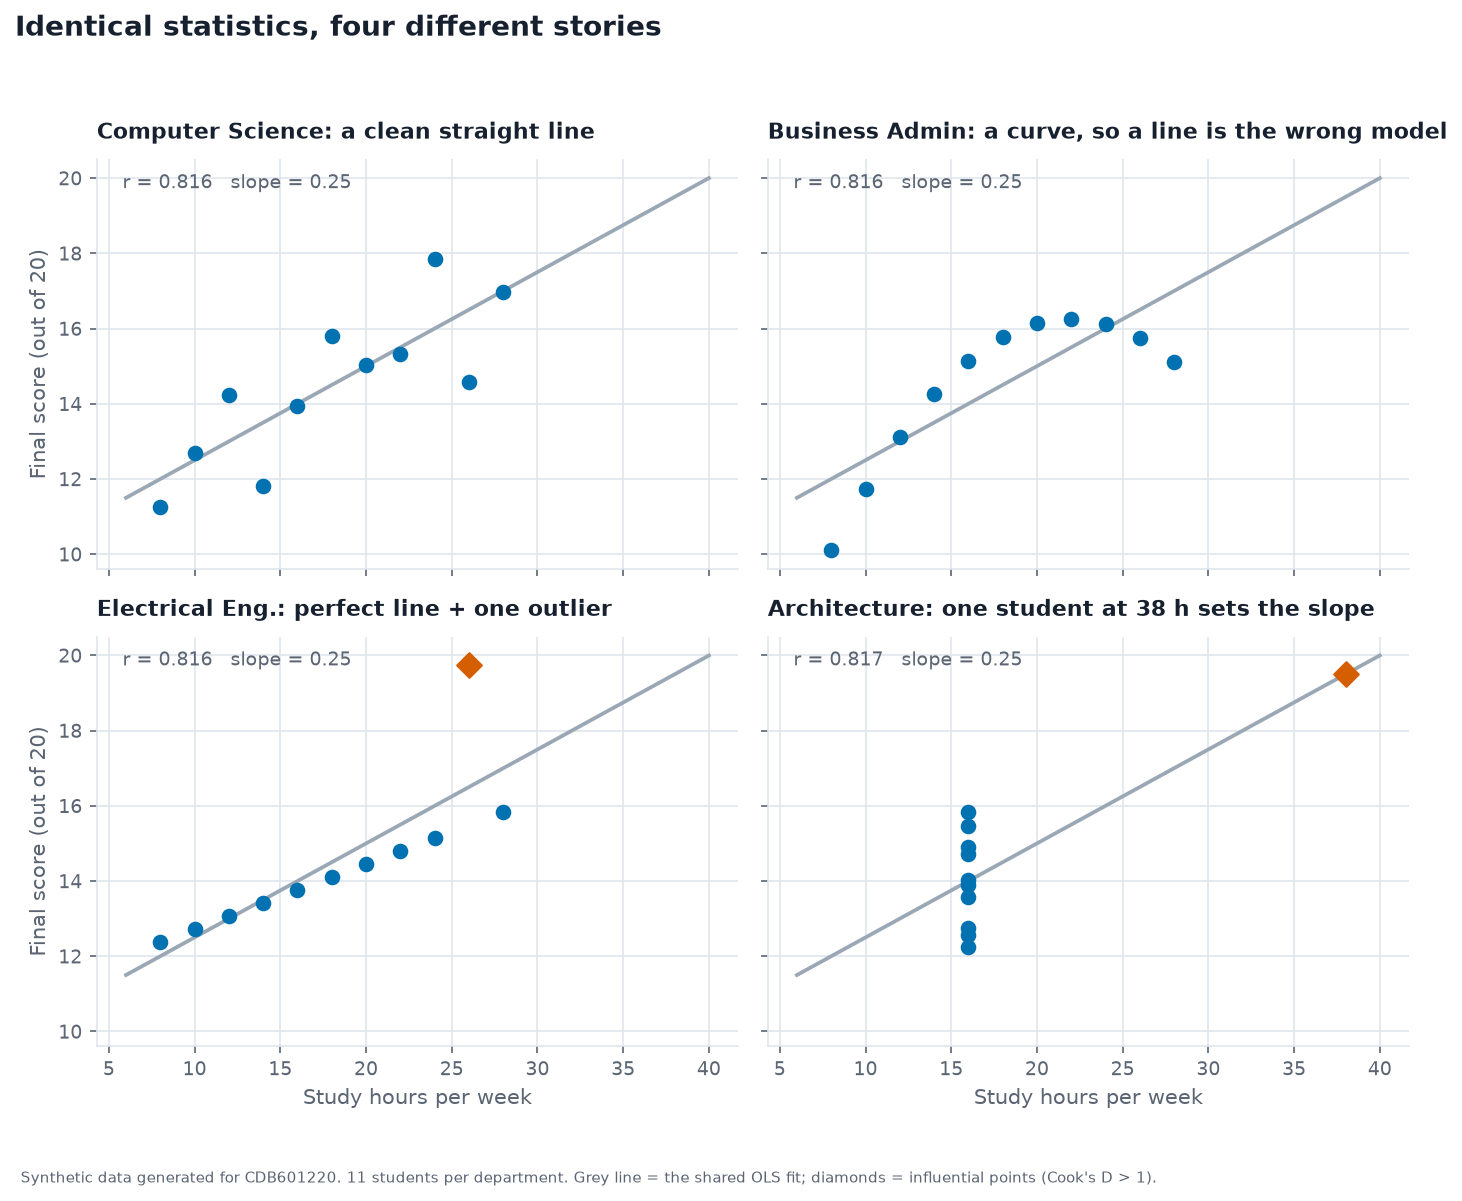

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(9.5, 7.6), sharex=True, sharey=True)
titles = {"Computer Science": "Computer Science: a clean straight line",
          "Business Administration": "Business Admin: a curve, so a line is the wrong model",
          "Electrical Engineering": "Electrical Eng.: perfect line + one outlier",
          "Architecture": "Architecture: one student at 38 h sets the slope"}
order4 = ["Computer Science", "Business Administration", "Electrical Engineering", "Architecture"]
xs = np.array([6, 40])
for ax, dep in zip(axes.flat, order4):
    d = c4[c4.department == dep]; x, y = d.study_hours_per_week.to_numpy(), d.final_score_out_of_20.to_numpy()
    b, a = np.polyfit(x, y, 1); res = y - (a + b * x)
    X = np.c_[np.ones_like(x), x]; h = np.diag(X @ np.linalg.inv(X.T @ X) @ X.T)
    cook = res ** 2 / (2 * (res ** 2).sum() / (len(x) - 2)) * h / (1 - h) ** 2
    flag = cook > 1                                         # Cook's D > 1: influential point
    ax.scatter(x[~flag], y[~flag], color=BLUE, s=42, zorder=3)
    ax.scatter(x[flag], y[flag], color=PALETTE["highlight"], s=70, marker="D", zorder=4)
    ax.plot(xs, a + b * xs, color=PALETTE["muted"], lw=1.8, zorder=2)
    ax.set_title(titles[dep], fontsize=10.5)
    ax.text(0.04, 0.93, f"r = {d.study_hours_per_week.corr(d.final_score_out_of_20):.3f}   slope = {b:.2f}",
            transform=ax.transAxes, fontsize=9, color=PALETTE["ink_soft"])
for ax in axes[1]: ax.set_xlabel("Study hours per week")
for ax in axes[:, 0]: ax.set_ylabel("Final score (out of 20)")
fig.suptitle("Identical statistics, four different stories", x=0.006, ha="left", fontsize=13.5, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
finish(fig, "A4_redesign", SYN + " 11 students per department. Grey line = the shared OLS fit; diamonds = influential points (Cook's D > 1).")

SUMMARY.append(dict(case=4, claim="Four departments identical, fund equally",
    decoy="Sampling noise? No: r agrees to 3 decimals; cohort_group is 1:1 with department",
    mechanism="Same mean/SD/r/slope, four shapes: line, curve, line + outlier, one leverage point (Anscombe)",
    number="Quadratic R2 1.000 vs 0.666 (BusAdmin); Cook's D 53.7 (Architecture); r 0.816 -> 1.000 without EE outlier"))

---
## Case 5 · "Five cohorts, one set of statistics"
*Recipe (not a chart): the same table, one column per `shape_name`.*

In [18]:
c5 = pd.read_csv(DATA / "case05_same_stats_shapes.csv")
t5 = summary_table(c5, "shape_name", "hours_on_platform", "assessment_score", ddof=0)   # population SD, as match_stats uses
t5 = t5.drop(index="slope")
display(t5.round(3))
assert (t5.loc["mean hours_on_platform"].round(2) == 48.00).all() and (t5.loc["mean assessment_score"].round(2) == 63.00).all()   # self-check
assert (t5.loc["SD hours_on_platform"].round(2) == 12.00).all() and (t5.loc["SD assessment_score"].round(2) == 15.00).all()
assert ((t5.loc["Pearson r"] - 0.420).abs() < 0.001).all()

,ring,star,straight line,the letter X,two clusters
n,180.00,180.00,180.00,180.00,180.00
mean hours_on_platform,48.00,48.00,48.00,48.00,48.00
mean assessment_score,63.00,63.00,63.00,63.00,63.00
SD hours_on_platform,12.00,12.00,12.00,12.00,12.00
SD assessment_score,15.00,15.00,15.00,15.00,15.00
Pearson r,0.42,0.42,0.42,0.42,0.42


In [19]:
# --- evidence: statistics that DO see the shape ---------------------------------------------
from scipy import stats as st
rows = {}
for k, d in c5.groupby("shape_name"):
    zx = (d.hours_on_platform - d.hours_on_platform.mean()) / d.hours_on_platform.std(ddof=0)
    zy = (d.assessment_score - d.assessment_score.mean()) / d.assessment_score.std(ddof=0)
    rad = np.hypot(zx, zy)
    rows[k] = {"n": len(d), "excess kurtosis of x": st.kurtosis(d.hours_on_platform),
               "closest point to centre (SD units)": rad.min(),
               "share within 0.5 SD of centre": (rad < 0.5).mean()}
display(pd.DataFrame(rows).T.round(2))

,n,excess kurtosis of x,closest point to centre (SD units),share within 0.5 SD of centre
ring,180.0,-1.48,1.00,0.00
star,180.0,-0.94,0.56,0.00
straight line,180.0,-1.20,0.08,0.10
the letter X,180.0,-1.20,0.02,0.22
two clusters,180.0,-1.78,0.55,0.00


**Conclusion the chart invites:** the five cohorts are the same: identical mean, SD and r = 0.42, so one intervention and one policy fit all of them.

**The decoy:** *"The samples are too small or too different in size."* Each cohort has **n = 180**, and mean, SD and r agree to the third decimal, because they were forced to (`vizlib.match_stats()` linearly transforms any shape to *exact* target statistics). So neither sample size nor sampling error is in play.

**The mechanism: five different shapes share one set of summary numbers.** The table cannot tell a line, a ring, a star, two clusters and the letter X apart. Statistics that look at *where the points are* can: **share of points within 0.5 SD of the centre is 0% for the ring, star and two clusters, 10% for the line and 22% for the X**; the ring has a hole (nearest point 1.00 SD from the centre) while the X and the line pass through it; excess kurtosis of hours ranges from **-1.78 (two clusters) to -0.94 (star)**. r = 0.42 describes a linear trend in only one of the five. For the ring and the X it describes nothing real at all.

**Redesign:** small multiples on shared axes, with the shared statistics printed once.

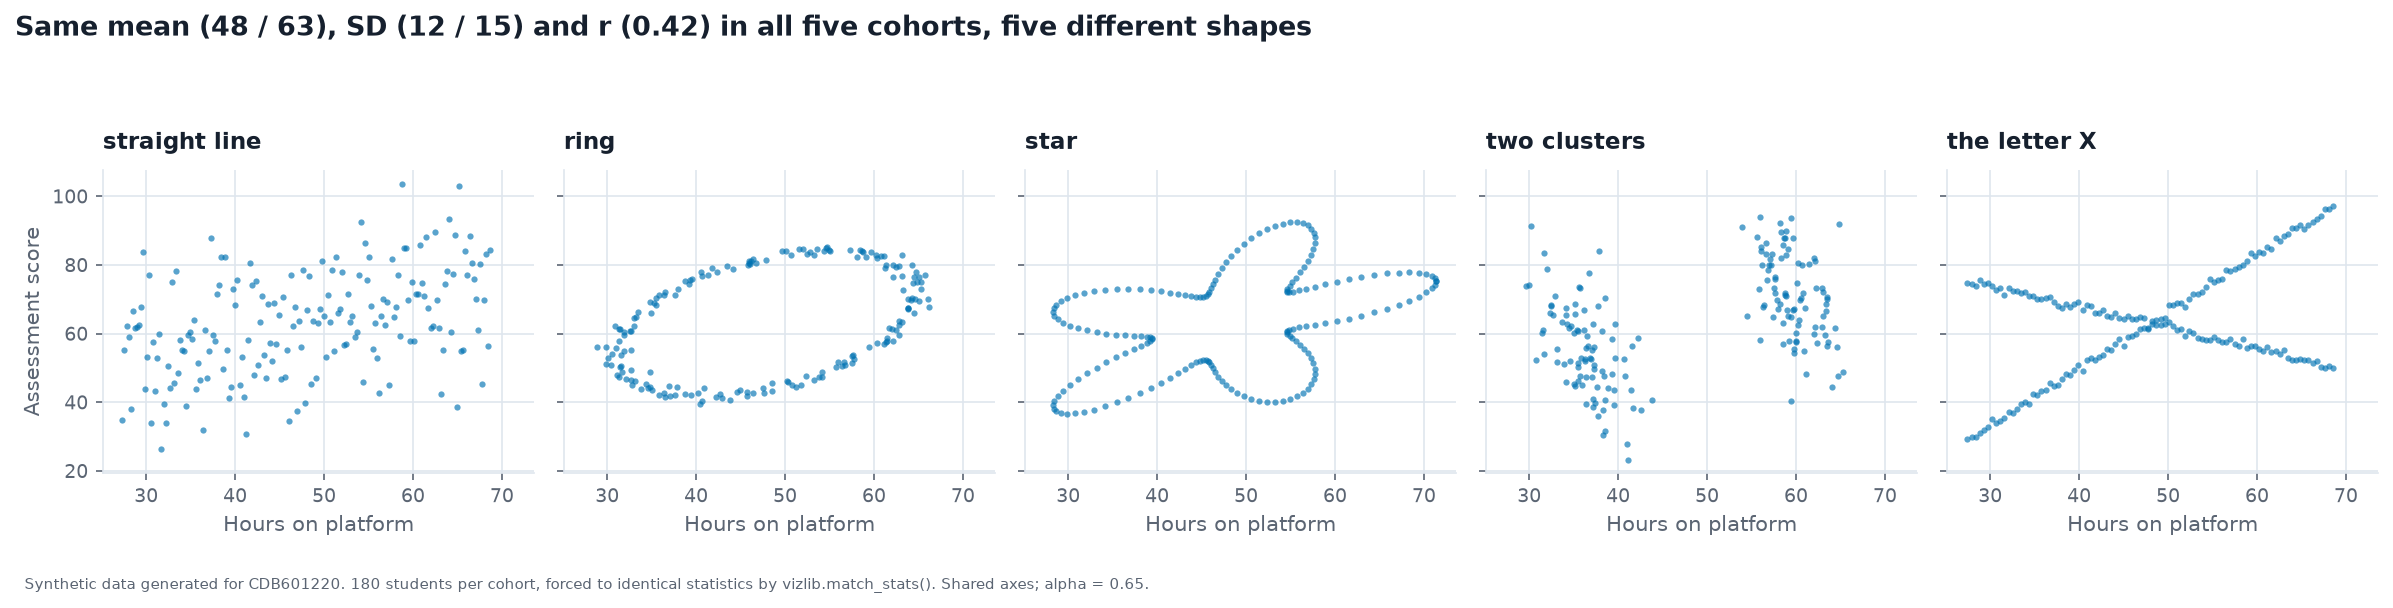

In [20]:
order5 = ["straight line", "ring", "star", "two clusters", "the letter X"]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.7), sharex=True, sharey=True)
for ax, k in zip(axes, order5):
    d = c5[c5.shape_name == k]
    ax.scatter(d.hours_on_platform, d.assessment_score, s=9, alpha=0.65, color=BLUE, linewidths=0)
    ax.set_title(k, fontsize=11); ax.set_xlabel("Hours on platform")
axes[0].set_ylabel("Assessment score")
fig.suptitle("Same mean (48 / 63), SD (12 / 15) and r (0.42) in all five cohorts, five different shapes", x=0.006, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.9])
finish(fig, "A5_redesign", SYN + " 180 students per cohort, forced to identical statistics by vizlib.match_stats(). Shared axes; alpha = 0.65.")

SUMMARY.append(dict(case=5, claim="Five cohorts, one set of statistics",
    decoy="Small / unequal samples? No: n = 180 each, statistics identical to 3 decimals by construction",
    mechanism="match_stats() forces any shape to exact mean/SD/r; five shapes (line, ring, star, 2 clusters, X) share them",
    number="Share within 0.5 SD of centre: 0% (ring/star/clusters) to 22% (X)"))

---
## Case 6 · "Creatinine tracks HbA1c: a finding"
*Recipe: correlation matrix of every numeric column except `age_band`, `study_site`, `hr_device_model`; annotated heatmap exactly as the analyst drew it: `cmap="Reds"`, no `vmin`/`vmax`, both triangles.*

(20, 20) | creatinine-hba1c = 0.77 | systolic-map_mmhg = 0.96


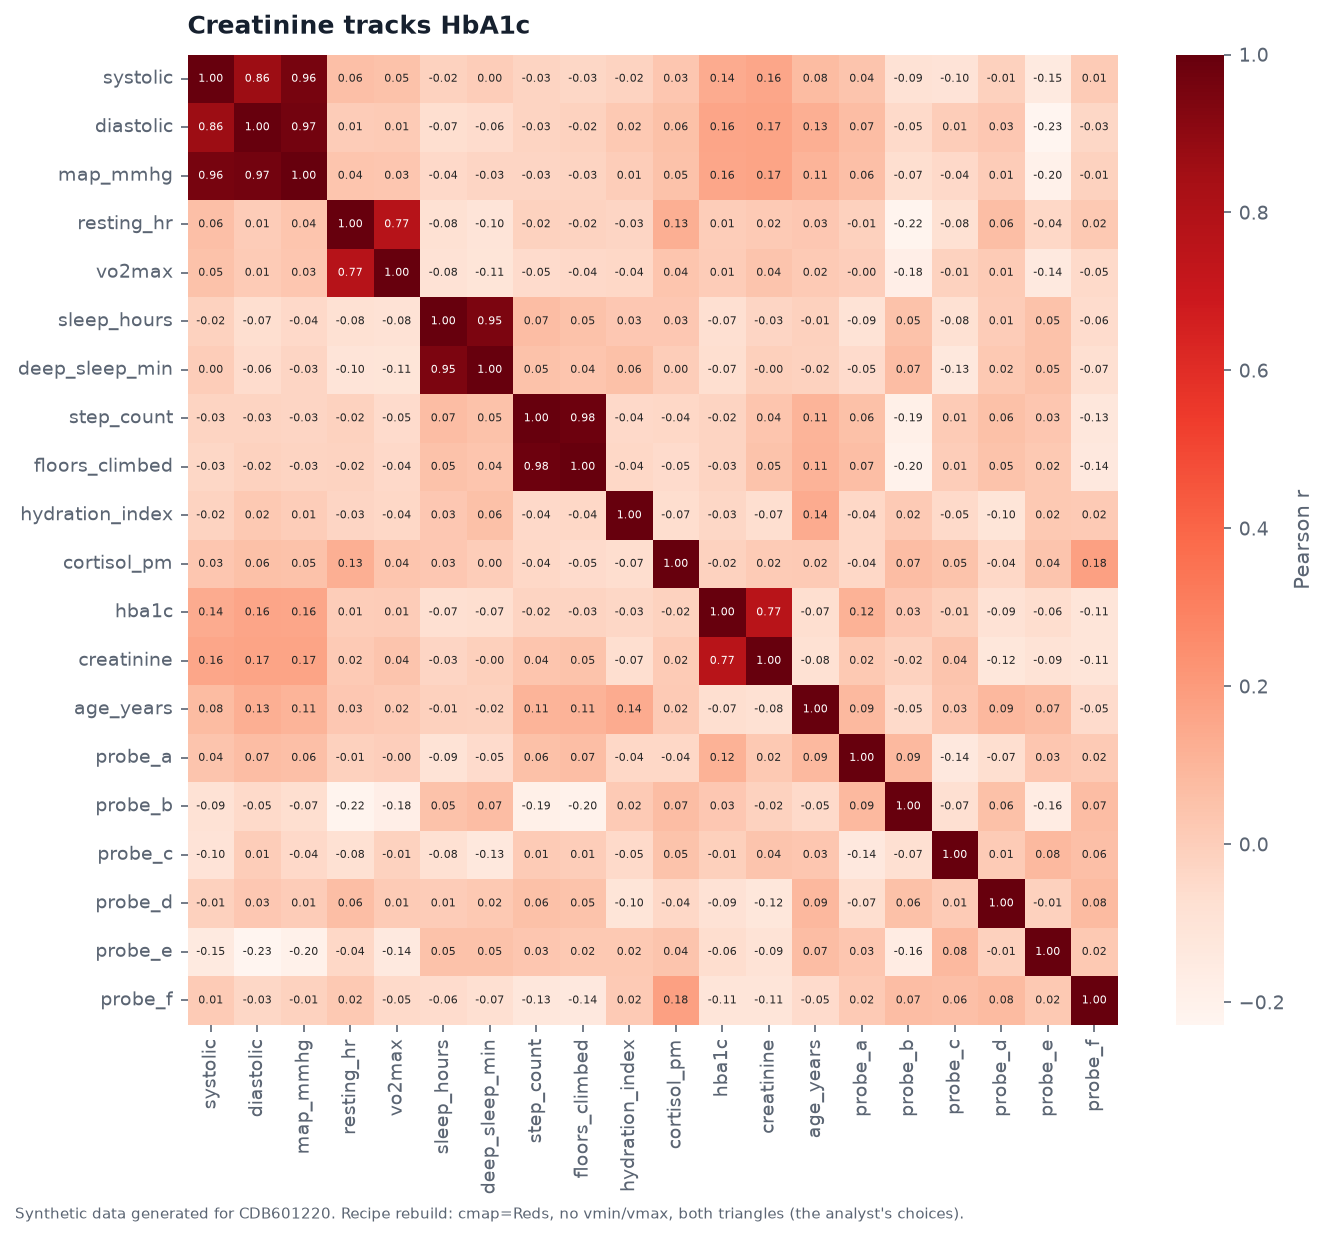

In [21]:
c6 = pd.read_csv(DATA / "case06_sensor_matrix.csv")
num = c6.drop(columns=["age_band", "study_site", "hr_device_model"]).select_dtypes("number")
corr6 = num.corr()
print(corr6.shape, "| creatinine-hba1c =", round(corr6.loc["creatinine", "hba1c"], 2),
      "| systolic-map_mmhg =", round(corr6.loc["systolic", "map_mmhg"], 2))
assert corr6.shape == (20, 20) and round(corr6.loc["creatinine", "hba1c"], 2) == 0.77 and round(corr6.loc["systolic", "map_mmhg"], 2) == 0.96   # self-check

fig, ax = plt.subplots(figsize=(10, 8.4))
sns.heatmap(corr6, cmap="Reds", annot=True, fmt=".2f", annot_kws={"size": 5.5}, ax=ax, cbar_kws={"label": "Pearson r"})   # no vmin/vmax, both triangles
ax.grid(False)
ax.set_title("Creatinine tracks HbA1c")
finish(fig, "A6_rebuild", SYN + " Recipe rebuild: cmap=Reds, no vmin/vmax, both triangles (the analyst's choices).")

In [22]:
# --- evidence 1: the DRAWING ----------------------------------------------------------------
vals = corr6.values
print(f"seaborn silently picked vmin = {vals.min():.2f}, vmax = {vals.max():.2f}")
print(f"negative cells: {(vals < 0).sum()} of {vals.size};  all {190} pairs are drawn twice; the 20 diagonal 1.00s stretch the scale")

# --- evidence 2: the MEANING ----------------------------------------------------------------
print("\nthe single most extreme participant:")
print(c6.loc[c6.creatinine.idxmax(), ["creatinine", "hba1c", "age_years", "study_site"]].to_string())
print(f"  next-highest creatinine in the other 179: {c6.creatinine.drop(c6.creatinine.idxmax()).max():.1f}   (cohort median {c6.creatinine.median():.1f})")
r_all, p_all = stats.pearsonr(c6.creatinine, c6.hba1c)
d179 = c6.drop(index=c6.creatinine.idxmax())
r_179, p_179 = stats.pearsonr(d179.creatinine, d179.hba1c)
print(f"\nr with all 180: {r_all:.3f} (p = {p_all:.0e})     r without that ONE row: {r_179:.3f} (p = {p_179:.2f})")
print(f"Spearman (rank-based, ignores size of the outlier): {stats.spearmanr(c6.creatinine, c6.hba1c)[0]:.3f}")

# decoy: 190 pairs -> chance hits?  The probe channels are noise; how big do chance correlations get?
probes = [c for c in num.columns if c.startswith("probe")]
chance = corr6.loc[probes].drop(columns=probes).abs().values.max()
print(f"\nlargest |r| involving a noise probe channel: {chance:.2f}   (so chance in 190 pairs reaches ~0.2, not 0.77)")

# the other strong pairs after removal
c179 = d179[num.columns].corr(); iu = np.triu_indices(20, 1)
strong = sorted([(abs(c179.values[i, j]), c179.index[i], c179.columns[j]) for i, j in zip(*iu) if abs(c179.values[i, j]) > 0.5], reverse=True)
print("\npairs with |r| > 0.5 once that row is removed:")
for v, a, b in strong: print(f"  {a:>14s} - {b:<14s} {c179.loc[a, b]:+.2f}")

seaborn silently picked vmin = -0.23, vmax = 1.00
negative cells: 180 of 400;  all 190 pairs are drawn twice; the 20 diagonal 1.00s stretch the scale

the single most extreme participant:
creatinine    1050.0
hba1c           15.8
age_years       30.0
study_site    Site C
  next-highest creatinine in the other 179: 111.4   (cohort median 81.5)

r with all 180: 0.765 (p = 7e-36)     r without that ONE row: -0.004 (p = 0.96)
Spearman (rank-based, ignores size of the outlier): 0.032

largest |r| involving a noise probe channel: 0.23   (so chance in 190 pairs reaches ~0.2, not 0.77)

pairs with |r| > 0.5 once that row is removed:
      step_count - floors_climbed +0.98
       diastolic - map_mmhg       +0.97
        systolic - map_mmhg       +0.96
     sleep_hours - deep_sleep_min +0.95
        systolic - diastolic      +0.86
      resting_hr - vo2max         +0.77


**This one is wrong in two separate ways, and fixing one does not fix the other.**

**(a) How it is *drawn*.** Single-hue `Reds` with no `vmin`/`vmax` makes seaborn stretch the scale over the data range (**-0.23 to 1.00**). The 20 diagonal 1.00s set the top; every negative correlation is nearly indistinguishable from zero because nothing in the palette signals sign; and the upper triangle repeats the lower, drawing each of 190 pairs twice. A correlation has a sign, so it needs a **diverging map pinned to -1…+1 with a neutral midpoint**, with the upper triangle masked.

**(b) What it *says*.** *Conclusion the chart invites:* kidney function (creatinine) and glycaemic control (HbA1c) are strongly related (r = 0.77), a clinically plausible finding.

*The decoy:* **"With 190 pairs, some will be significant by chance."** That is true in general and irrelevant here: the largest correlation involving a pure-noise probe channel is only **0.23**, and r = 0.77 has p ≈ 7e-36. Chance does not reach 0.77.

*The mechanism:* **one participant.** Row 0 has creatinine **1,050 µmol/L** (the next highest of the other 179 is **111.4**; the median is about 82) and HbA1c **15.8%** (a physiologically extreme pair, almost certainly an entry or device error). That single point lies far out on both axes and creates the whole correlation. **Remove it and r goes from 0.77 to -0.004** (p = 0.96); the rank-based Spearman, which ignores the outlier's size, is 0.03. Also visible: `map_mmhg` vs systolic/diastolic (0.96, 0.97) is arithmetic because MAP is computed from them; step count and floors climbed, and sleep hours and deep sleep, are the same behaviour measured twice.

**Which fix solves which:** repainting the heatmap (diverging, pinned, masked) fixes (a) and the figure becomes honest about *sign*, but it will still show the 0.77, because the number is a correct summary of a contaminated column. Only a **scatter plot** (or removing and declaring the row) exposes (b).

**Redesign:** the scatter that reveals the outlier, then the corrected heatmap with that row excluded and declared.

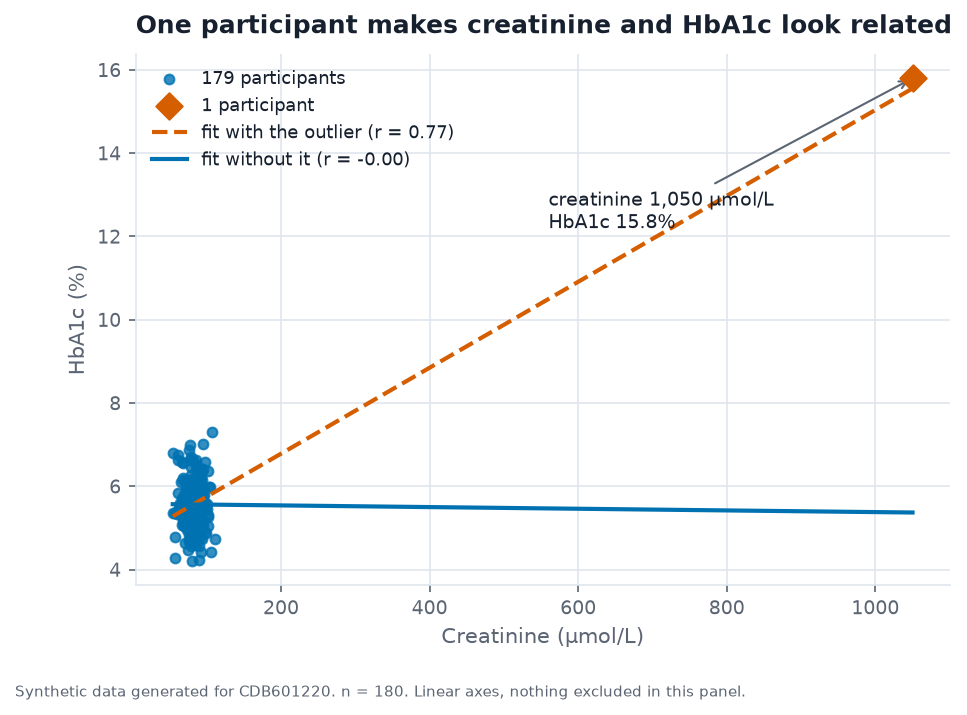

In [23]:
# --- 6a: the scatter that shows what the heatmap hides ------------------------------------
i_out = c6.creatinine.idxmax()
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.scatter(d179.creatinine, d179.hba1c, color=BLUE, s=22, alpha=0.8, label="179 participants")
ax.scatter(c6.loc[i_out, "creatinine"], c6.loc[i_out, "hba1c"], color=PALETTE["highlight"], marker="D", s=80, zorder=4, label="1 participant")
xs = np.array([c6.creatinine.min(), c6.creatinine.max()])
b_all, a_all = np.polyfit(c6.creatinine, c6.hba1c, 1); b_179, a_179 = np.polyfit(d179.creatinine, d179.hba1c, 1)
ax.plot(xs, a_all + b_all * xs, color=PALETTE["highlight"], ls="--", label=f"fit with the outlier (r = {r_all:.2f})")
ax.plot(xs, a_179 + b_179 * xs, color=BLUE, label=f"fit without it (r = {r_179:.2f})")
ax.annotate("creatinine 1,050 µmol/L\nHbA1c 15.8%", xy=(c6.loc[i_out, "creatinine"], c6.loc[i_out, "hba1c"]),
            xytext=(560, 12.2), fontsize=9, arrowprops=dict(arrowstyle="->", color=PALETTE["ink_soft"]))
ax.set_xlabel("Creatinine (µmol/L)"); ax.set_ylabel("HbA1c (%)")
ax.set_title("One participant makes creatinine and HbA1c look related")
ax.legend(loc="upper left", fontsize=8.5)
finish(fig, "A6_redesign_scatter", SYN + " n = 180. Linear axes, nothing excluded in this panel.")

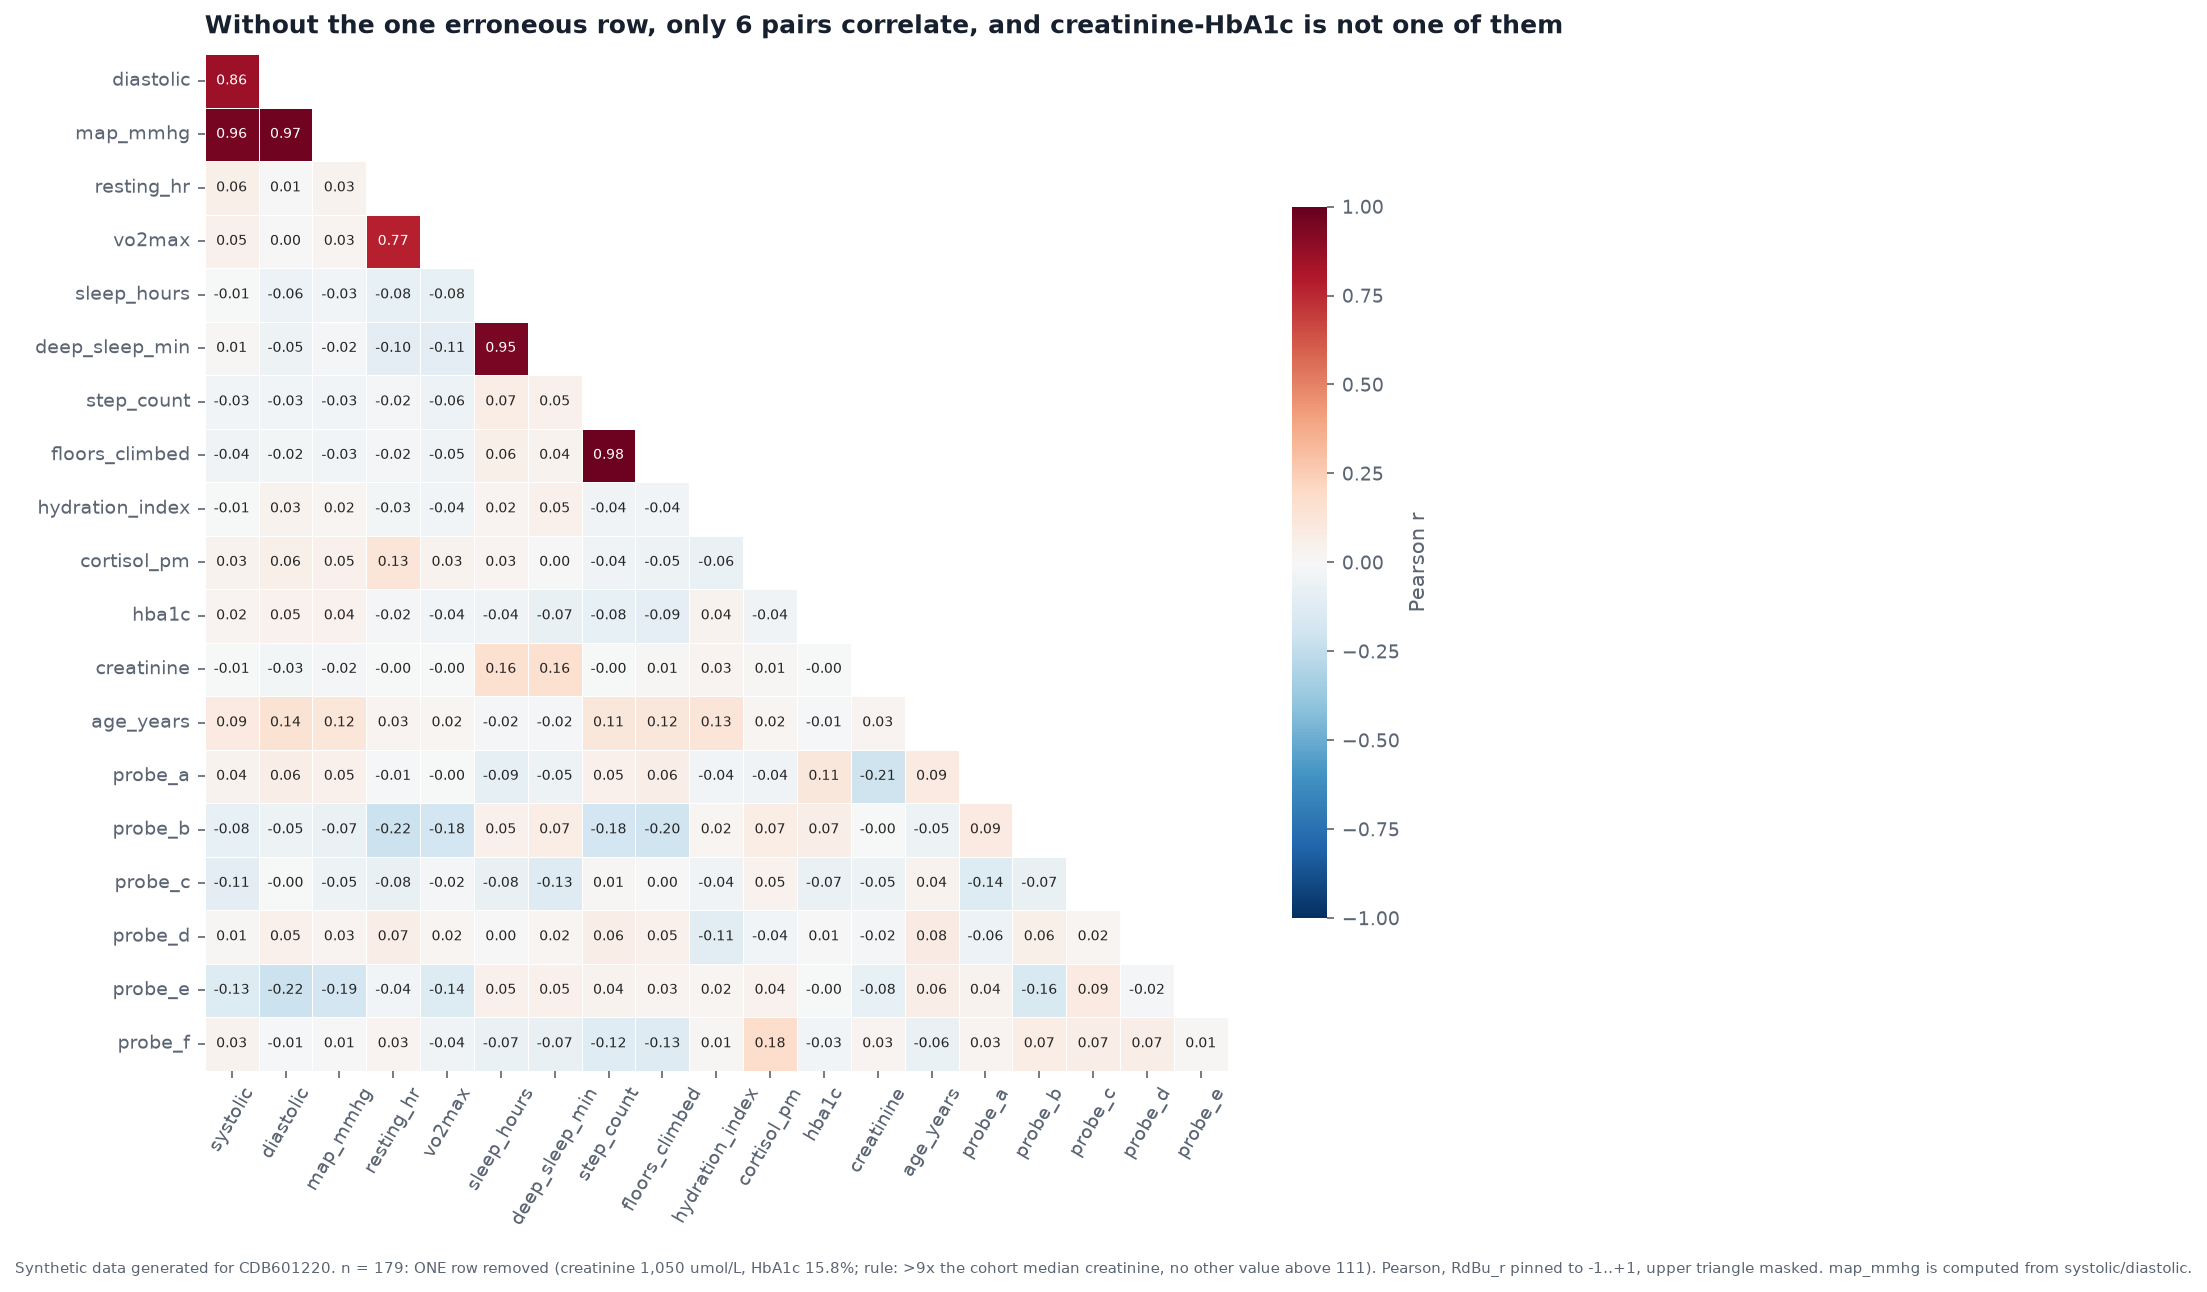

In [24]:
# --- 6b: the corrected heatmap, with the one row removed and declared ------------------------
corr_fix = d179[num.columns].corr()
sub = corr_fix.iloc[1:, :-1]                                  # drop empty first row / last column
mask = np.triu(np.ones_like(sub, dtype=bool), k=1)           # upper triangle masked
n_strong = len(strong)
fig, ax = plt.subplots(figsize=(11, 8.8))
sns.heatmap(sub, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 6.5}, linewidths=0.4, linecolor="white", cbar_kws={"label": "Pearson r", "shrink": 0.7}, ax=ax)
ax.grid(False)
ax.set_title(f"Without the one erroneous row, only {n_strong} pairs correlate, and creatinine-HbA1c is not one of them")
ax.tick_params(axis="x", rotation=60)
finish(fig, "A6_redesign_heatmap", SYN + " n = 179: ONE row removed (creatinine 1,050 umol/L, HbA1c 15.8%; rule: >9x the cohort median creatinine, "
       "no other value above 111). Pearson, RdBu_r pinned to -1..+1, upper triangle masked. map_mmhg is computed from systolic/diastolic.")

SUMMARY.append(dict(case=6, claim="Creatinine tracks HbA1c (r=0.77)",
    decoy="190 pairs, chance? No: chance reaches ~0.23 (noise probes); p of 0.77 is ~7e-36",
    mechanism="One participant (creatinine 1,050, HbA1c 15.8) makes the correlation. Drawing flaw: Reds with no vmin/vmax hides sign",
    number="r 0.77 -> -0.004 without that one row"))

---
## Case 7 · "ShaheenGo ran at a loss until May"
*Recipe: line chart with **two y-axes**: `revenue_pkr_m` on the left limited to 50-80, `cost_pkr_m` on the right limited to 40-56 (`ax.twinx()`).*
(The one dual-axis chart in this work, rebuilt only so it can be taken apart.)

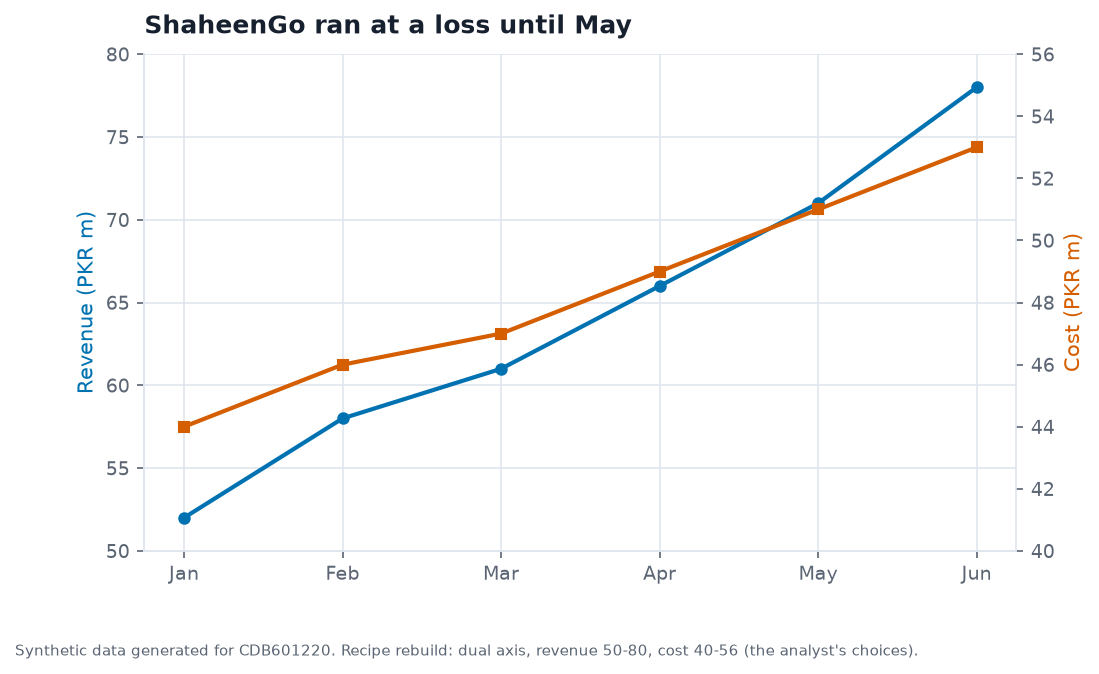

cost line drawn above revenue line: [True, True, True, True, False, False]


In [25]:
c7 = pd.read_csv(DATA / "case07_dual_axis_series.csv")
fig, ax1 = plt.subplots(figsize=(7.5, 4.3))
ax2 = ax1.twinx()
ax1.plot(c7.month, c7.revenue_pkr_m, color=BLUE, marker="o", label="Revenue (left)")
ax2.plot(c7.month, c7.cost_pkr_m, color=ORANGE, marker="s", label="Cost (right)")
ax1.set_ylim(50, 80); ax2.set_ylim(40, 56)
ax2.grid(False); ax2.spines["right"].set_visible(True)
ax1.set_ylabel("Revenue (PKR m)", color=BLUE); ax2.set_ylabel("Cost (PKR m)", color=ORANGE)
ax1.set_title("ShaheenGo ran at a loss until May")
finish(fig, "A7_rebuild", SYN + " Recipe rebuild: dual axis, revenue 50-80, cost 40-56 (the analyst's choices).")

# self-check: where do the two lines sit on screen?
pos_rev = (c7.revenue_pkr_m - 50) / (80 - 50)
pos_cost = (c7.cost_pkr_m - 40) / (56 - 40)
print("cost line drawn above revenue line:", (pos_cost > pos_rev).tolist())
assert (pos_cost > pos_rev).tolist()[:4] == [True] * 4                       # self-check: first four months

In [26]:
# --- evidence: the data, on one scale --------------------------------------------------------
ev = c7.assign(profit=c7.revenue_pkr_m - c7.cost_pkr_m,
               margin=lambda d: d.profit / d.revenue_pkr_m)
display(ev.style.format({"margin": "{:.1%}"}))
print("Revenue > cost in every month:", bool((ev.profit > 0).all()))

,month,revenue_pkr_m,cost_pkr_m,profit,margin
0,Jan,52,44,8,15.4%
1,Feb,58,46,12,20.7%
2,Mar,61,47,14,23.0%
3,Apr,66,49,17,25.8%
4,May,71,51,20,28.2%
5,Jun,78,53,25,32.1%


Revenue > cost in every month: True


**Conclusion the chart invites:** the business lost money until May, when revenue finally crossed above cost.

**The decoy:** *"The two measures are in different units, so they need two axes."* They are not: **both columns are PKR millions** (see the data dictionary). Same unit means one axis is possible, and obligatory if you want to compare them.

**The mechanism: two independent axis ranges set the picture.** Each line is positioned by its own limits (50-80 and 40-56), so where the lines *cross on screen* says nothing about the data. The analyst chose ranges that make the cost line sit above revenue until May. **In the data revenue exceeds cost in every single month**: the gap is **PKR 8 m in January and 25 m in June**, a margin that rises from **15.4% to 32.1%**. There was never a loss.

**Redesign:** one shared axis from zero for the levels, and the gap itself as a second panel (two panels, not two axes).

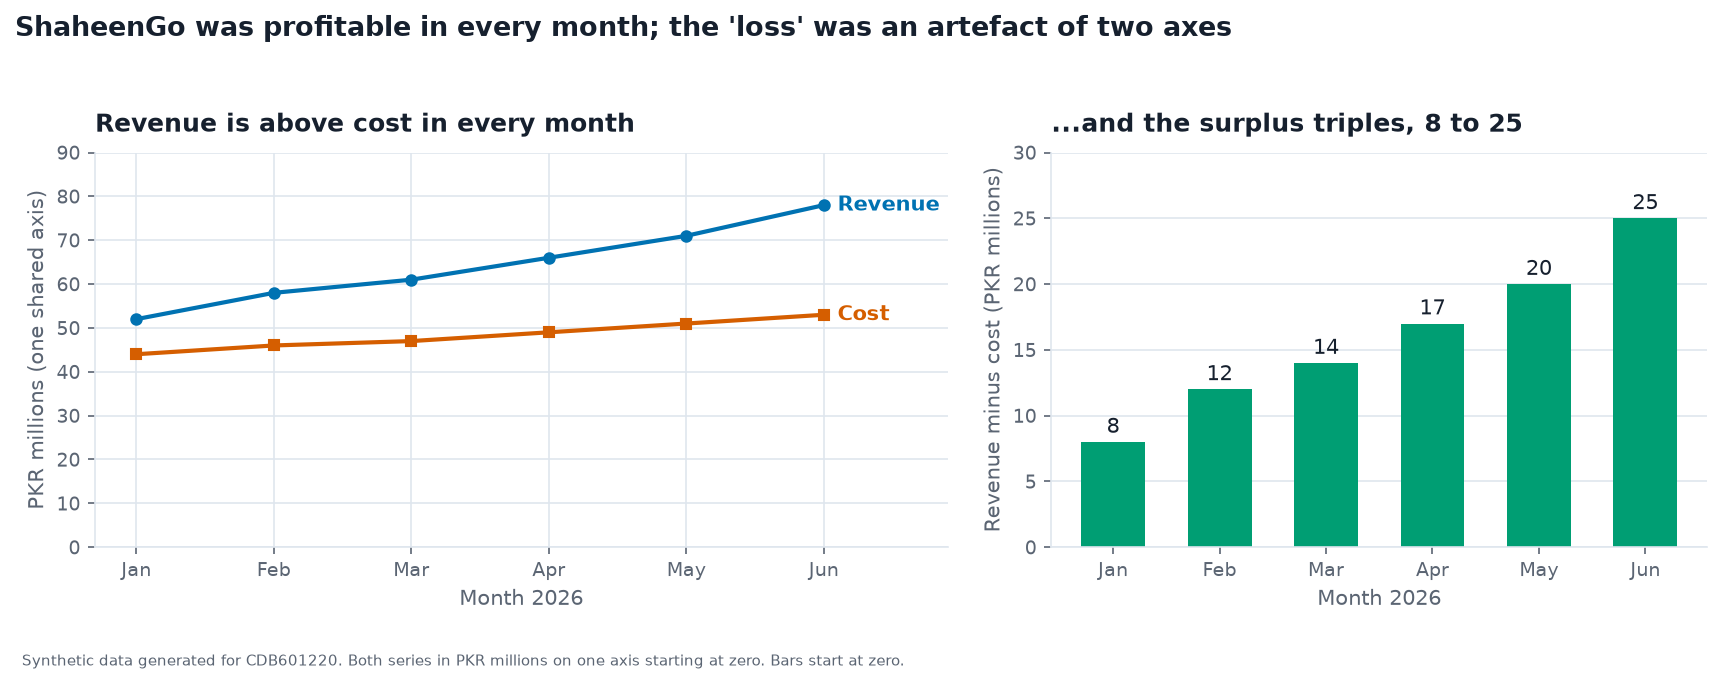

In [27]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
a1.plot(c7.month, c7.revenue_pkr_m, color=BLUE, marker="o", lw=2)
a1.plot(c7.month, c7.cost_pkr_m, color=ORANGE, marker="s", lw=2)
a1.text(5.1, c7.revenue_pkr_m.iloc[-1], "Revenue", color=BLUE, va="center", fontweight="bold")
a1.text(5.1, c7.cost_pkr_m.iloc[-1], "Cost", color=ORANGE, va="center", fontweight="bold")
a1.set_ylim(0, 90); a1.set_xlim(-0.3, 5.9)
a1.set_ylabel("PKR millions (one shared axis)"); a1.set_xlabel("Month 2026")
a1.set_title("Revenue is above cost in every month")

bars = a2.bar(ev.month, ev.profit, color=GREEN, width=0.6)
a2.bar_label(bars, fmt="%d", padding=2)
a2.set_ylim(0, 30); a2.set_ylabel("Revenue minus cost (PKR millions)"); a2.set_xlabel("Month 2026")
a2.set_title("...and the surplus triples, 8 to 25"); a2.grid(axis="x", visible=False)
fig.suptitle("ShaheenGo was profitable in every month; the 'loss' was an artefact of two axes", x=0.006, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
finish(fig, "A7_redesign", SYN + " Both series in PKR millions on one axis starting at zero. Bars start at zero.")

SUMMARY.append(dict(case=7, claim="ShaheenGo ran at a loss until May",
    decoy="Different units need two axes? No: both are PKR millions",
    mechanism="Independent axis ranges (50-80, 40-56) place the lines; the data has revenue > cost every month",
    number="Gap 8 to 25 PKR m; margin 15.4% to 32.1%"))

---
## Case 8 · "Three bin widths, three different distributions"
*Recipe: three histograms of `systolic` side by side, sharing nothing: `bins=3`, `bins=45`, `bins=400`.*

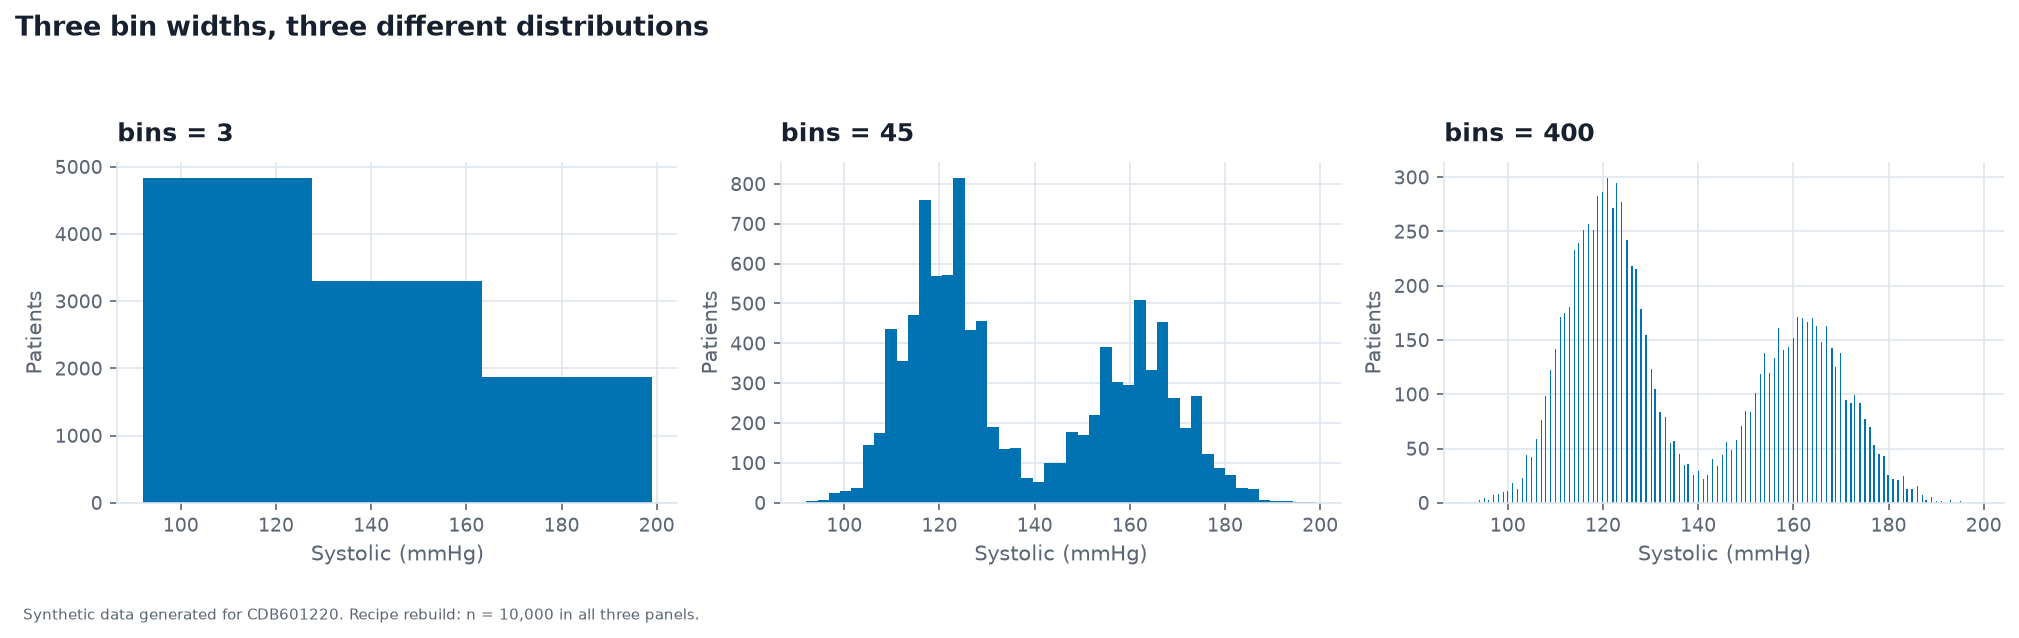

In [28]:
v = pd.read_csv(DATA / "vitals_10k.csv")
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))
for ax, b in zip(axes, (3, 45, 400)):
    counts, edges, _ = ax.hist(v.systolic, bins=b, color=BLUE)
    assert counts.sum() == 10_000                                           # self-check: n in every panel
    ax.set_title(f"bins = {b}"); ax.set_xlabel("Systolic (mmHg)"); ax.set_ylabel("Patients")
fig.suptitle("Three bin widths, three different distributions", x=0.006, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.92])
finish(fig, "A8_rebuild", SYN + " Recipe rebuild: n = 10,000 in all three panels.")

In [29]:
# --- evidence -------------------------------------------------------------------------------
s = v.systolic.to_numpy()
print(f"distinct systolic values (whole mmHg): {len(np.unique(s))}   range {s.min()}-{s.max()}   n = {len(s):,}")
for b in (3, 45, 400):
    h, e = np.histogram(s, bins=b)
    print(f"bins={b:>3}: width {e[1]-e[0]:6.2f} mmHg   empty bins {(h == 0).sum():>3}   n = {h.sum():,}")
iqr = np.subtract(*np.percentile(s, [75, 25])); fd = 2 * iqr / len(s) ** (1 / 3)
print(f"Freedman-Diaconis width = {fd:.2f} mmHg  ->  I use 4 mmHg, aligned to whole-mmHg edges")

edges4 = np.arange(90, 204, 4); h4, _ = np.histogram(s, bins=edges4); c4_ = (edges4[:-1] + edges4[1:]) / 2
lo_m = c4_[c4_ < 135][h4[c4_ < 135].argmax()]; hi_m = c4_[c4_ >= 135][h4[c4_ >= 135].argmax()]
print(f"modes (4-mmHg bins): {lo_m:.0f} and {hi_m:.0f} mmHg;  share above 140 mmHg: {(s > 140).mean():.1%}")

distinct systolic values (whole mmHg): 104   range 92-199   n = 10,000
bins=  3: width  35.67 mmHg   empty bins   0   n = 10,000
bins= 45: width   2.38 mmHg   empty bins   0   n = 10,000
bins=400: width   0.27 mmHg   empty bins 296   n = 10,000
Freedman-Diaconis width = 3.81 mmHg  ->  I use 4 mmHg, aligned to whole-mmHg edges
modes (4-mmHg bins): 120 and 164 mmHg;  share above 140 mmHg: 41.6%


**Conclusion the chart invites:** the distribution of systolic pressure depends on who drew it: one blob, a bumpy two-peak shape, or a spiky mess, so histograms are untrustworthy.

**The decoy:** *"The sample is too small / noisy."* It is not: **n = 10,000 in every panel** (the self-check), with identical data in all three.

**The mechanism: bin width is a parameter, and two of these values are wrong in opposite directions.**
- **`bins=3`** → 35.7 mmHg per bin: far wider than the gap between the two populations, so they are averaged into **one blob** (the hidden structure is the story).
- **`bins=400`** → 0.27 mmHg per bin, **finer than the measurement itself**. Systolic is recorded in whole mmHg (**104 distinct values**), so **296 of the 400 bins are empty** and the rest hold single integer values: a picket fence that is an artefact of the *recording*, not of patients.
- **`bins=45`** (2.4 mmHg) happens to resolve the real shape: **two populations, modes near 120 and 164 mmHg, 42% of patients above 140**. The data did not change; the analyst's choice did.

**Redesign:** one histogram with a *declared*, defensible width (4 mmHg; Freedman-Diaconis suggests 3.8), aligned to whole-mmHg edges.

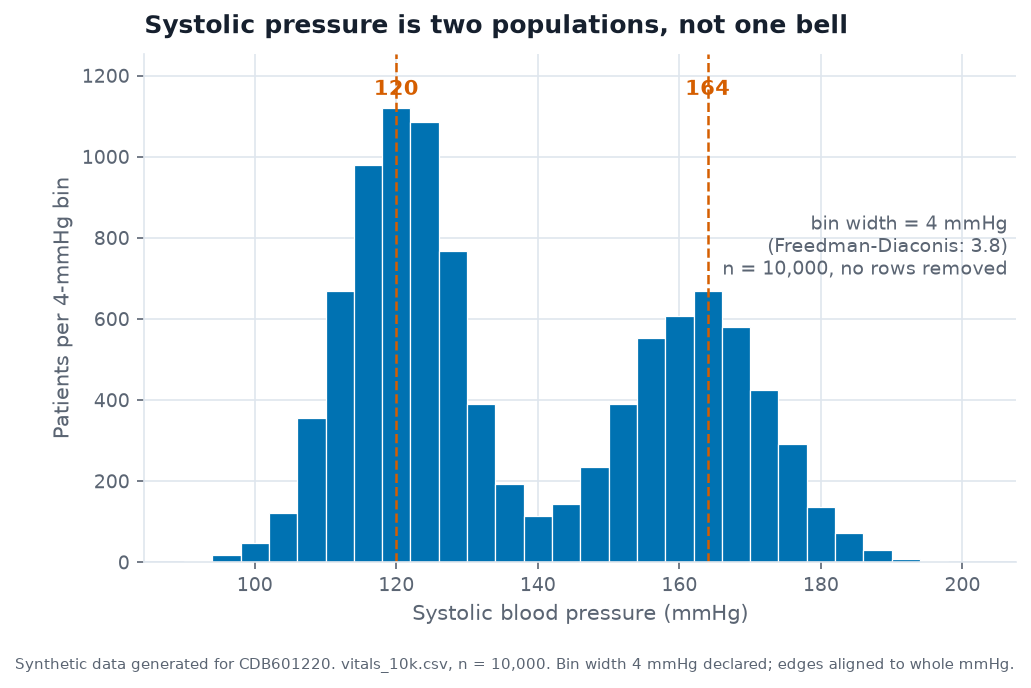

In [30]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
counts, edges, _ = ax.hist(s, bins=edges4, color=BLUE, edgecolor="white", lw=0.6)
for m in (lo_m, hi_m):
    ax.axvline(m, color=PALETTE["highlight"], ls="--", lw=1.2)
ax.text(lo_m, counts.max() * 1.03, f"{lo_m:.0f}", ha="center", color=PALETTE["highlight"], fontweight="bold")
ax.text(hi_m, counts.max() * 1.03, f"{hi_m:.0f}", ha="center", color=PALETTE["highlight"], fontweight="bold")
ax.set_ylim(0, counts.max() * 1.12)
ax.set_xlabel("Systolic blood pressure (mmHg)"); ax.set_ylabel("Patients per 4-mmHg bin")
ax.set_title("Systolic pressure is two populations, not one bell")
ax.text(0.99, 0.62, "bin width = 4 mmHg\n(Freedman-Diaconis: 3.8)\nn = 10,000, no rows removed", transform=ax.transAxes,
        ha="right", va="center", fontsize=9, color=PALETTE["ink_soft"])
finish(fig, "A8_redesign", SYN + " vitals_10k.csv, n = 10,000. Bin width 4 mmHg declared; edges aligned to whole mmHg.")

SUMMARY.append(dict(case=8, claim="Three bin widths, three distributions",
    decoy="Small / noisy sample? No: n = 10,000 in every panel",
    mechanism="Bin width is a parameter: 3 bins merge two populations; 400 bins are finer than whole-mmHg data (296 empty)",
    number="Modes 120 and 164 mmHg; 42% above 140; 104 distinct values"))

---
## Case 9 · "4.4% of the density sits above 100% saturation"
*Recipe: kernel density estimate of `spo2` with the **default** bandwidth; extend the x-axis to 108; mark 100.*

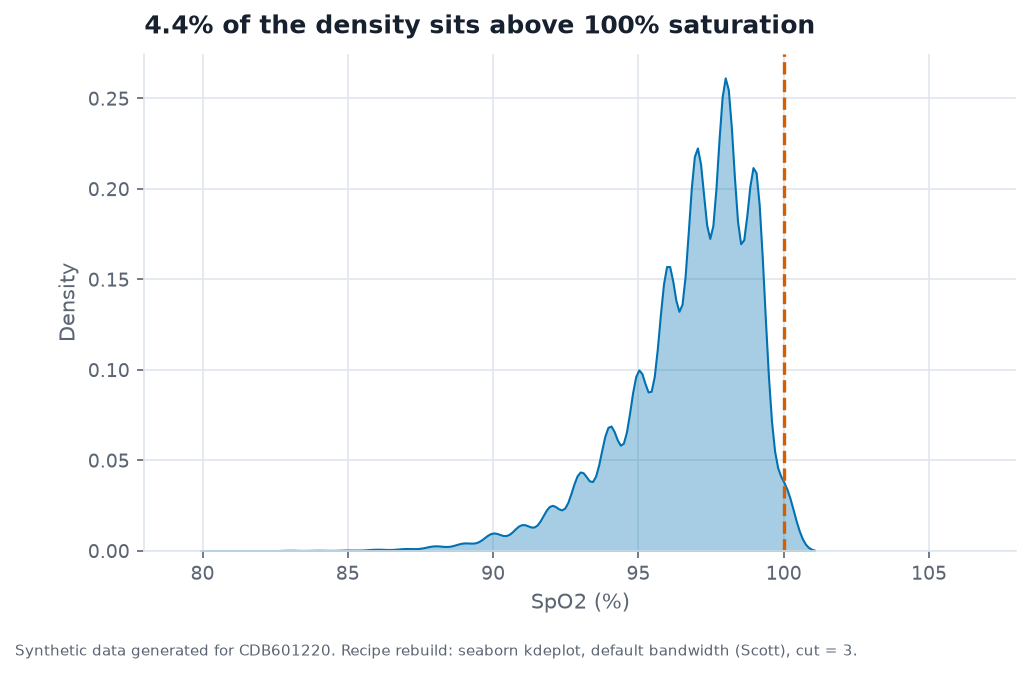

data maximum: 100


In [31]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
sns.kdeplot(x=v.spo2, ax=ax, color=BLUE, fill=True, alpha=0.35)          # defaults: bw_method="scott", bw_adjust=1, cut=3
ax.axvline(100, color=PALETTE["highlight"], ls="--", lw=1.6)
ax.set_xlim(78, 108)
ax.set_xlabel("SpO2 (%)"); ax.set_ylabel("Density")
ax.set_title("4.4% of the density sits above 100% saturation")
finish(fig, "A9_rebuild", SYN + " Recipe rebuild: seaborn kdeplot, default bandwidth (Scott), cut = 3.")

x_curve = ax.lines[0].get_xdata() if ax.lines else None
print("data maximum:", v.spo2.max())                                       # self-check
assert v.spo2.max() == 100

In [32]:
# --- evidence -------------------------------------------------------------------------------
from scipy.stats import gaussian_kde
x = v.spo2.to_numpy(dtype=float)
kde = gaussian_kde(x)                                                       # same estimator seaborn uses by default
grid = np.linspace(60, 130, 70001); dens = kde(grid); dx = grid[1] - grid[0]
print(f"bandwidth: factor {kde.factor:.3f} x sample SD {x.std(ddof=1):.2f} = kernel SD {np.sqrt(kde.covariance[0, 0]):.2f} points")
print(f"KDE mass above 100: {dens[grid > 100].sum() * dx:.1%}      readings above 100 in the data: {(x > 100).sum()}")
print(f"share of patients reading exactly 100: {(x == 100).mean():.1%};  at 99 or 100: {(x >= 99).mean():.1%};  distinct values: {len(np.unique(x))}")
print("\nsensitivity: KDE mass above 100 as the bandwidth grows")
for adj in (0.5, 1, 2, 2.5, 3):
    k = gaussian_kde(x, bw_method=kde.factor * adj); print(f"  bw x{adj}: {k(grid)[grid > 100].sum() * dx:.1%}")

bandwidth: factor 0.158 x sample SD 2.24 = kernel SD 0.35 points
KDE mass above 100: 1.6%      readings above 100 in the data: 0
share of patients reading exactly 100: 3.0%;  at 99 or 100: 21.4%;  distinct values: 20

sensitivity: KDE mass above 100 as the bandwidth grows
  bw x0.5: 1.5%
  bw x1: 1.6%
  bw x2: 3.0%
  bw x2.5: 4.2%
  bw x3: 5.4%


**Conclusion the chart invites:** a measurable share of patients have impossible oxygen saturation above 100%, so there are sensor errors or a data problem to chase.

**The decoy:** *"Some readings must exceed 100: the sensor is faulty."* Ruled out directly: the **maximum in the data is exactly 100** and **zero readings are above it**. The curve extends past 100; the data does not.

**The mechanism: the kernel estimator does not know 100 is a wall.** A KDE replaces every reading with a small bell curve (here SD ≈ 0.35 points, Scott's rule: factor 0.158 × the sample SD of 2.24). Saturation is **discrete** (20 whole-number values, 81-100) and **piled up against a ceiling**: **3.0% of patients read exactly 100 and 21.4% read 99 or 100**. The bells on those readings are symmetric, so about half of each spills past 100 into territory where no measurement can exist. In my run that spilled mass is **1.6%** of the density at the default bandwidth, and it grows with the bandwidth (4.2% at 2.5× the default, 5.4% at 3×). **The percentage is an artefact of smoothing a bounded, discrete variable.** (The 4.4% in the title does not reproduce at the default bandwidth: I get 1.6%. The exact figure depends on the smoother's settings, which is itself the point; the qualitative claim, a curve that continues past a physical maximum, is what holds.)

**Redesign:** don't smooth a ceiling; show the count at each whole-number reading.

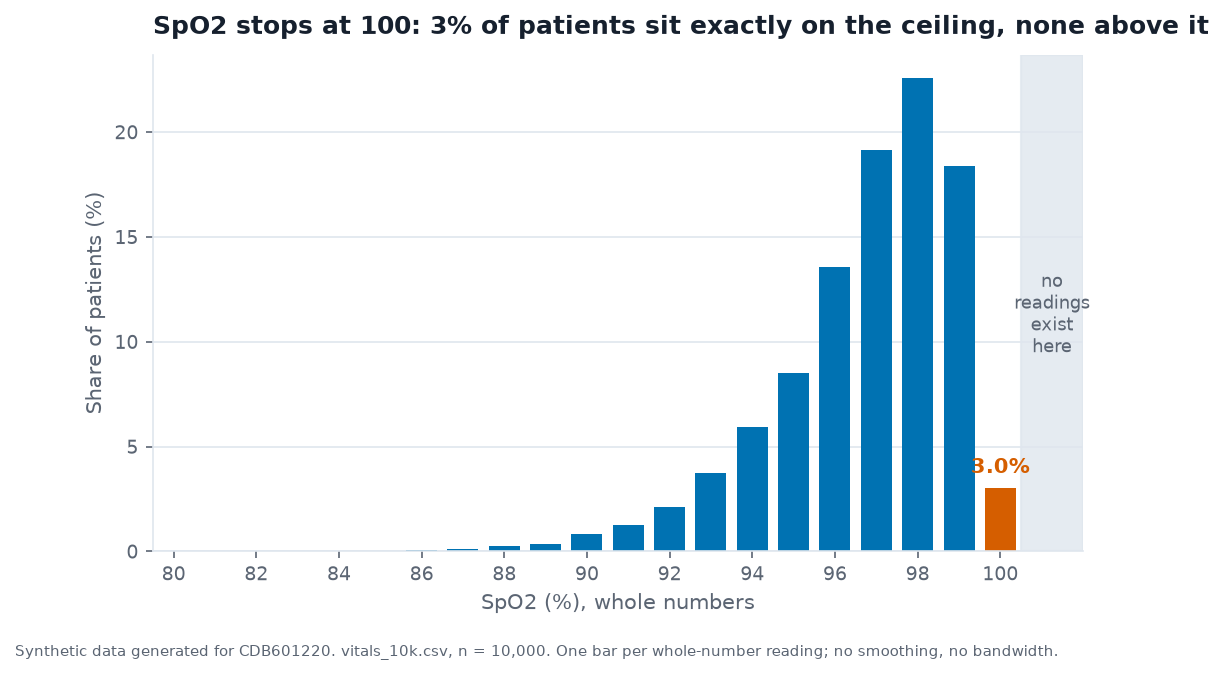

In [33]:
vc = v.spo2.value_counts().sort_index()
share = vc / vc.sum() * 100
fig, ax = plt.subplots(figsize=(8, 4.3))
colors = [PALETTE["highlight"] if i == 100 else BLUE for i in share.index]
bars = ax.bar(share.index, share.values, color=colors, width=0.75)
ax.set_xlim(79.5, 102); ax.set_xticks(range(80, 101, 2))
ax.axvspan(100.5, 102, color=PALETTE["grid"], alpha=0.8, zorder=0)
ax.text(101.25, share.max() * 0.5, "no\nreadings\nexist\nhere", ha="center", va="center", fontsize=8.5, color=PALETTE["ink_soft"])
ax.text(100, share[100] + 0.7, f"{share[100]:.1f}%", ha="center", color=PALETTE["highlight"], fontweight="bold")
ax.set_xlabel("SpO2 (%), whole numbers"); ax.set_ylabel("Share of patients (%)")
ax.set_title("SpO2 stops at 100: 3% of patients sit exactly on the ceiling, none above it")
ax.grid(axis="x", visible=False)
finish(fig, "A9_redesign", SYN + " vitals_10k.csv, n = 10,000. One bar per whole-number reading; no smoothing, no bandwidth.")

SUMMARY.append(dict(case=9, claim="4.4% of density above 100% saturation",
    decoy="Readings above 100 / sensor fault? No: data max is exactly 100, zero values above",
    mechanism="KDE ignores the ceiling: 3.0% of readings sit exactly at 100 and each bell spills past it",
    number="1.6% spill at default bandwidth (4.2% at 2.5x); 304 patients at exactly 100"))

---
## Summary of all nine diagnoses (for the PDF)

In [34]:
summary = pd.DataFrame(SUMMARY).set_index("case")
pd.set_option("display.max_colwidth", None)
display(summary.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,claim,decoy,mechanism,number
case,,,,
1,Premium helmets: 2.5x injury rate,Premium riders less experienced? No: 31.4 vs 31.5 months,Road type confounds (Simpson): 85% of Premium trips on the motorway (6.1/1000); Premium lower within every road,Motorway 6.00 vs 8.00; 340/400 Premium on motorway
2,Chai sales predict quiz failures (r=0.98),Exam months? No: r stays 0.996 inside exam and non-exam months,"Enrolment tripled (1,765 to 5,406); both series scale with it (r=0.997, 0.977)",Per-student r = 0.29 (p=0.16); R^2 0.96 -> 0.09
3,Smog plan cut AQI by a third (202 to 137),Seasonal weather? No: the 13 stations that always report are flat (137.1 vs 137.2),9 highest-AQI stations (6 Industrial + 3 Arterial) stop reporting on day 61; the mean skips blanks,22 to 13 stations reporting; like-for-like +0.1%
4,"Four departments identical, fund equally",Sampling noise? No: r agrees to 3 decimals; cohort_group is 1:1 with department,"Same mean/SD/r/slope, four shapes: line, curve, line + outlier, one leverage point (Anscombe)",Quadratic R2 1.000 vs 0.666 (BusAdmin); Cook's D 53.7 (Architecture); r 0.816 -> 1.000 without EE outlier
5,"Five cohorts, one set of statistics","Small / unequal samples? No: n = 180 each, statistics identical to 3 decimals by construction","match_stats() forces any shape to exact mean/SD/r; five shapes (line, ring, star, 2 clusters, X) share them",Share within 0.5 SD of centre: 0% (ring/star/clusters) to 22% (X)
6,Creatinine tracks HbA1c (r=0.77),"190 pairs, chance? No: chance reaches ~0.23 (noise probes); p of 0.77 is ~7e-36","One participant (creatinine 1,050, HbA1c 15.8) makes the correlation. Drawing flaw: Reds with no vmin/vmax hides sign",r 0.77 -> -0.004 without that one row
7,ShaheenGo ran at a loss until May,Different units need two axes? No: both are PKR millions,"Independent axis ranges (50-80, 40-56) place the lines; the data has revenue > cost every month",Gap 8 to 25 PKR m; margin 15.4% to 32.1%
8,"Three bin widths, three distributions","Small / noisy sample? No: n = 10,000 in every panel",Bin width is a parameter: 3 bins merge two populations; 400 bins are finer than whole-mmHg data (296 empty),Modes 120 and 164 mmHg; 42% above 140; 104 distinct values
9,4.4% of density above 100% saturation,"Readings above 100 / sensor fault? No: data max is exactly 100, zero values above",KDE ignores the ceiling: 3.0% of readings sit exactly at 100 and each bell spills past it,1.6% spill at default bandwidth (4.2% at 2.5x); 304 patients at exactly 100


## What this notebook wrote
`outputs/` now holds each rebuild (`A#_rebuild.png`) and each redesign (`A#_redesign*.png`). Export the notebook (see README) for your `partA_diagnosis.pdf`.

In [35]:
for p in sorted(OUT.glob("A*.png")):
    print(p.name)

A1_rebuild.png
A1_redesign.png
A2_rebuild.png
A2_redesign.png
A3_rebuild.png
A3_redesign.png
A4_redesign.png
A5_redesign.png
A6_rebuild.png
A6_redesign_heatmap.png
A6_redesign_scatter.png
A7_rebuild.png
A7_redesign.png
A8_rebuild.png
A8_redesign.png
A9_rebuild.png
A9_redesign.png
